<div align="left">

# **Grupo 16 · Diplomatura en Ciencia de Datos · Proyecto Final Integrador**
## **Autores:** Emanuel Aguirre · María Alejandra Arocena · Juan Pablo Luna · Horacio Javier Ortiz

### Modelo Predictivo para Priorización y Triaje de ACV

</div>

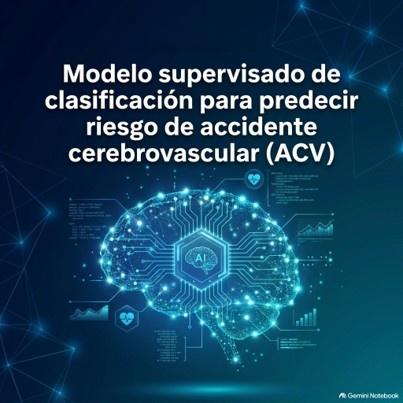

### Flujo de Trabajo Integrado y Estructura del Cuaderno (CRISP-DM)

#### PARTE 1: COMPRENSIÓN DEL NEGOCIO Y DE LOS DATOS (SECCIONES 0 A 2)

* **Sección 0: Configuración Inicial y Reproducibilidad**
  * Semilla aleatoria fija (`SEED = 42`), descarga del dataset e importación de librerías.
* **Sección 1: Carga, Limpieza y Calidad de Datos**
  * Eliminación de la columna `id` y del único registro `gender = 'Other'`.
  * Alcance estricto: **población adulta** ($18$ años o más).
  * Traducción de variables y auditoría de calidad (valores nulos, atípicos y mecanismo de faltantes del IMC).
* **Sección 2: Análisis Exploratorio y Pruebas de Hipótesis**
  * Gráficos exploratorios, cálculo de **Riesgos Relativos (RR)** con IC 95%, pruebas de Chi-cuadrado, t de Welch y Mann-Whitney.

---

#### PARTE 2: PREPARACIÓN Y MODELADO (SECCIONES 3 A 6)

* **Sección 3: Separación Train / Test**
  * División **80% / 20% estratificada**, garantizando la ausencia de fuga de información (*data leakage*).
* **Sección 4: Benchmark de Negocio**
  * Evaluación de la regla clínica simple: **edad $\ge 60$ o hipertensión**.
* **Sección 5: Pipeline de Preprocesamiento**
  * Imputación predictiva del IMC, escalado estándar de continuas y codificación One-Hot de categóricas.
* **Sección 6: Modelado y Selección**
  * Comparativa de **Regresión Logística, Random Forest y XGBoost** (versiones base u optimizadas) mediante validación cruzada anidada $5 \times 3$ utilizando **PR-AUC** como métrica técnica principal.
  * Selección del modelo por criterio de parsimonia y calibración de umbrales sobre predicciones *Out-Of-Fold* (OOF): operativo ($\text{Recall} \ge 60\%$), mismo esfuerzo y mismo Recall que la regla tradicional.
  * Generación de curvas Precision-Recall y de Ganancia Acumulada.

---

#### PARTE 3: EVALUACIÓN, INTERPRETABILIDAD, IMPACTO Y CONCLUSIONES (SECCIONES 7 A 10)

* **Sección 7: Evaluación Definitiva sobre el Conjunto de Test**
  * Evaluación de la capacidad discriminativa en *Test Holdout* (**PR-AUC**), verificación transparente de KPIs y análisis de incertidumbre mediante **Bootstrap pareado (IC 95%)**.
* **Sección 8: Interpretabilidad del Modelo Final**
  * Análisis de coeficientes, **Odds Ratios** e **importancia de características por permutación**.
* **Sección 9: Traducción a Números de Negocio y Análisis de Equidad Diagnóstica**
  * **9.1 Impacto Operativo:** Proyección lineal a escala de **10.000 adultos** ($18$ años o más).
  * **9.2 Equidad y Sesgo Algorítmico:** Evaluación de subgrupos por **género** y **residencia** (urbana/rural) utilizando **PR-AUC** (métrica principal), **Recall** (métrica secundaria) y porcentaje de población citada.
* **Sección 10: Conclusiones, Limitaciones y Próximos Pasos**
  * Resumen automatizado de métricas con Bootstrap pareado, balance de gestión, marco ético y hoja de ruta.

---

#### Criterios y Métricas Clave del Proyecto:

* **Métrica técnica principal:** **PR-AUC** (evaluación intrínseca de capacidad discriminativa global).
* **Métrica secundaria operativa:** **Recall $\ge 60\%$** (evaluada en conjunto con Precision y el % de población citada).
* **KPI de focalización:** Capturar $\ge 70\%$ de los casos de ACV priorizando como máximo al $\le 40\%$ de la población de mayor riesgo.

# 0. Configuración Inicial y Reproducibilidad

### Guía y Explicación de Librerías Importadas

#### 1. Gestión de Avisos, Tiempos y Estilos Básicos
* **`warnings`**: Oculta alertas secundarias del sistema para mantener la ejecución limpia y legible.
* **`time`**: Permite auditar y reportar de manera empírica el consumo de tiempo de cómputo de cada algoritmo durante la validación cruzada.
* **`SEED = 42`**: Fija una semilla aleatoria universal para garantizar que las particiones de datos y algoritmos generen exactamente los mismos resultados en cualquier computadora.

#### 2. Manipulación de Datos y Análisis Estadístico
* **`numpy` (`np`)**: Manejo de vectores, matrices y operaciones matemáticas de alto rendimiento.
* **`pandas` (`pd`)**: Creación y manipulación de tablas de datos (*DataFrames*).
* **`scipy.stats`**: Pruebas estadísticas de hipótesis (ej. test $t$ de Welch, Mann-Whitney) y distribuciones de probabilidad.

#### 3. Visualización de Datos
* **`matplotlib.pyplot` (`plt`)**: Creación gráfica fundamental (curvas, dispersión, barras).
* **`seaborn` (`sns`)**: Gráficos estadísticos avanzados (matrices de confusión, mapas de calor, distribuciones).

#### 4. Preprocesamiento y Arquitectura en Scikit-Learn
* **`BaseEstimator`, `TransformerMixin`**: Clases base para crear **transformadores personalizados** (ej. la imputación propia del IMC dentro del pipeline sin fuga de información).
* **`OneHotEncoder`**: Convierte variables categóricas (como estado civil o tipo de trabajo) en vectores numéricos binarios ($0$ o $1$).
* **`StandardScaler`**: Normaliza las variables numéricas para que tengan media $0$ y desviación estándar $1$, evitando que diferencias en escalas distorsionen los algoritmos.
* **`Pipeline` y `ColumnTransformer`**: Ensamblan los pasos de preprocesamiento y modelado en un único objeto, previniendo estrictamente la fuga de datos (*Data Leakage*).

#### 5. Validación y Optimización de Modelos
* **`train_test_split`**: Divide la base inicial en subconjuntos independientes de Entrenamiento (*Train*) y Evaluación (*Test*).
* **`StratifiedKFold` / `RepeatedStratifiedKFold`**: Esquemas de validación cruzada que mantienen la misma proporción de casos de ACV en cada fold (crucial al haber solo ~5.8 % de positivos entre los adultos).
* **`loguniform`**: Distribución de probabilidad para muestrear hiperparámetros continuos de forma logarítmicamente uniforme en búsquedas aleatorias.
* **`RandomizedSearchCV` / `GridSearchCV`**: Algoritmos para automatizar la búsqueda inteligente de los mejores hiperparámetros del modelo.

#### 6. Algoritmos de Machine Learning
* **`LogisticRegression`**: Modelo lineal base, altamente interpretable mediante *Odds Ratios*.
* **`RandomForestClassifier`**: Algoritmo ensemble basado en múltiples árboles de decisión con pesos balanceados de clase.
* **`XGBClassifier`**: Algoritmo de *Gradient Boosting* de última generación, optimizado para alto rendimiento en datos estructurados y desbalanceados.

#### 7. Métricas de Evaluación Operativa e Interpretabilidad
* **`average_precision_score` (PR-AUC)**: Métrica principal para medir la capacidad de discriminación en clases severamente desbalanceadas.
* **`precision_recall_curve`**: Permite evaluar y ajustar el **umbral probabilístico operativo** para maximizar el Recall según las necesidades del centro de salud.
* **`confusion_matrix` / `ConfusionMatrixDisplay`**: Matriz para contabilizar y graficar Falsos Positivos, Falsos Negativos, Verdaderos Positivos y Verdaderos Negativos.
* **`permutation_importance`**: Método robusto de interpretabilidad agnóstico al modelo que mide la caída del rendimiento al permutar aleatoriamente cada variable.

In [1]:
import warnings
warnings.filterwarnings("ignore")

# 1. Instalar y descargar el dataset directamente desde Kaggle
!pip install -q kagglehub
import kagglehub
import os

# Descarga la última versión del dataset de fedesoriano desde Kaggle
path = kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")
print("Ruta del dataset descargado:", path)

# Asignamos la ruta al archivo CSV descargado
DATA_PATH = os.path.join(path, "healthcare-dataset-stroke-data.csv")

# 2. Importación de Librerías Estándar, Científicas y de Visualización
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from scipy import stats
from scipy.stats import loguniform
from matplotlib.ticker import PercentFormatter

# Scikit-learn: clases base, transformaciones y pipelines
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Scikit-learn: Esquemas de validación cruzada y búsqueda de hiperparámetros
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    RandomizedSearchCV,
    GridSearchCV,
    cross_val_predict
)

# Modelos Supervisados
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Métricas de Evaluación Operativa e Interpretabilidad
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

# Constantes y Configuración Global de Visualización
SEED = 42

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False
})

print("\n Entorno de ejecución e importaciones inicializadas correctamente al 100% sin redundancias.")

Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Ruta del dataset descargado: /kaggle/input/stroke-prediction-dataset

 Entorno de ejecución e importaciones inicializadas correctamente al 100% sin redundancias.


# 1. Carga, Limpieza y Normalización de Datos

En esta sección aplicamos las reglas de limpieza y preparación inicial de la base de datos para garantizar la consistencia sin incurrir en fuga de información (*Data Leakage*).

#### 1. Carga e Ingesta de Datos
* **`pd.read_csv(DATA_PATH)`**: Consume el dataset localizado en la ruta definida en la configuración de Kaggle.
* **`df.columns.str.strip().str.lower()`**: Normaliza los nombres de las columnas a minúsculas y remueve espacios para evitar errores de sintaxis (ej. `Residence_type` pasa a ser `residence_type`).

#### 2. Criterios de Limpieza y Filtrado Técnico
* **Eliminación de `id` (`df.drop`)**: Se descarta el identificador único del paciente por no aportar valor predictivo o clínico.
* **Depuración de categorías residuales (`gender != 'Other'`)**: Se excluye un único registro asignado a `'Other'`, ya que no conforma una muestra estadísticamente representativa.
* **Filtrado por edad (`df['age'] >= 18`)**: El modelo se limita a personas de **18 años o más**, que son la población objetivo de un programa de prevención de ACV. El ACV pediátrico es poco frecuente (≈ 1 a 2 casos cada 100.000 niños por año) y responde a otras causas (arteriopatías no ateroscleróticas, cardiopatías congénitas, trastornos de la coagulación) que no están entre las variables del dataset (revisión *Acute ischemic stroke in childhood: a comprehensive review*, PMC8760225). En los datos, los 856 menores aportaban solo 2 de los 249 casos. Al filtrar, la categoría `'children'` de la situación laboral desaparece. Usamos `.copy()` para evitar advertencias de copia encadenada (*SettingWithCopyWarning*).
* **Outliers**: Se conservan intactos los valores biológicamente plausibles de IMC y nivel de glucosa en lugar de recurrir a la Winsorización, evitando así alterar artificialmente el perfil de riesgo real de los pacientes con mayor vulnerabilidad clínica.

#### 3. Preservación del Test Set (Fuga de Información)
* **Manejo de Nulos (`bmi`)**: Los valores faltantes de IMC **no se imputan en esta etapa**. Calcular la mediana sobre todo el dataset antes de dividir en *Train* y *Test* expondría al modelo a información del conjunto de prueba. La imputación por mediana según edad y género se ejecutará dentro del `Pipeline` exclusivamente con datos de entrenamiento.

In [2]:
# Carga de la base de datos desde la ruta local de Kaggle
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

# Normalizar nombres de columnas a minúsculas sin espacios
df.columns = df.columns.str.strip().str.lower()
print("Tamaño original:", df.shape)

# Aplicar reglas de limpieza y filtrado
df = df.drop(columns=["id"])
df = df[df["gender"] != "Other"].copy()

# Filtrar para conservar solo personas mayores o iguales a 18 años
df = df[df["age"] >= 18].copy()

# Reporte de estado tras la limpieza
print("Tamaño luego de limpieza (y filtrado >= 18 años):", df.shape)
print(f"Prevalencia de ACV (Target): {df['stroke'].mean():.1%}")
print("\nNulos por columna:")
print(df.isna().sum()[df.isna().sum() > 0])

# Visualizar primeras filas
df.head()

Tamaño original: (5110, 12)
Tamaño luego de limpieza (y filtrado >= 18 años): (4253, 11)
Prevalencia de ACV (Target): 5.8%

Nulos por columna:
bmi    181
dtype: int64


,gender,age,hypertension,heart_disease,ever_married,work_type,residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.000,0,1,Yes,Private,Urban,228.690,36.600,formerly smoked,1
1,Female,61.000,0,0,Yes,Self-employed,Rural,202.210,NaN,never smoked,1
2,Male,80.000,0,1,Yes,Private,Rural,105.920,32.500,never smoked,1
3,Female,49.000,0,0,Yes,Private,Urban,171.230,34.400,smokes,1
4,Female,79.000,1,0,Yes,Self-employed,Rural,174.120,24.000,never smoked,1


#### **Inspección de Estructura e Identificación de Variables (Inglés)**

Antes de proceder con la transformación, realizamos una lectura directa de la lista de nombres de columnas originales del *dataset*. Esto nos permite verificar la correcta lectura de la base de datos y tener una referencia clara de las variables en su idioma original.

In [3]:
# 1. Inspeccionar nombres actuales de las columnas
print("Variables actuales en el DataFrame:")
print(list(df.columns))

Variables actuales en el DataFrame:
['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']


#### **Traducción y Estandarización de Variables al Español**

Para facilitar el análisis exploratorio de datos (EDA), la interpretación clínica y la lectura gráfica en las siguientes secciones, aplicamos una traducción integral:

1. **Estandarización de Nombres de Columnas:** Renombramos las variables clínicas y demográficas a español (ej. `age` $\rightarrow$ `edad`, `stroke` $\rightarrow$ `acv`, `avg_glucose_level` $\rightarrow$ `nivel_glucosa_promedio`).
2. **Traducción de Categorías Cualitativas:** Mapeamos los valores internos de las variables categóricas (`genero`, `casado`, `tipo_trabajo`, `tipo_residencia`, `fuma`) para garantizar una lectura intuitiva en las tablas y gráficos sin alterar la distribución de la información.

> **Nota Metodológica sobre `tipo_trabajo`:** Traducimos `'Never_worked'` como `'No_trabaja'`. Entre los adultos, esta categoría queda con **solo 5 personas y ningún ACV**. Mantenemos la variable `tipo_trabajo` en el modelo como factor de contexto socio-laboral, pero su coeficiente para `No_trabaja` se estima con muy pocos casos y **no debe interpretarse clínicamente**. Además, configuramos el `OneHotEncoder` con `handle_unknown="ignore"` (§5) para que la validación cruzada no falle cuando esa categoría no aparece en un pliegue de entrenamiento.

In [4]:
# 2. Renombrar columnas y traducir valores internos de forma compacta
diccionario_columnas = {
    'gender': 'genero',
    'age': 'edad',
    'hypertension': 'hipertension',
    'heart_disease': 'enfermedad_cardiaca',
    'ever_married': 'casado',
    'work_type': 'tipo_trabajo',
    'residence_type': 'tipo_residencia',
    'avg_glucose_level': 'nivel_glucosa_promedio',
    'bmi': 'imc',
    'smoking_status': 'fuma',
    'stroke': 'acv'
}
df = df.rename(columns=diccionario_columnas)

# Diccionario consolidado para traducciones internas (incluyendo Never_worked -> No_trabaja)
traducciones_valores = {
    'genero': {'Male': 'Masculino', 'Female': 'Femenino'},
    'casado': {'Yes': 'Si', 'No': 'No'},
    'tipo_trabajo': {
        'Private': 'Privado',
        'Self-employed': 'Independiente',
        'Govt_job': 'Empleado_Publico',
        'Never_worked': 'No_trabaja'
    },
    'tipo_residencia': {'Urban': 'Urbana', 'Rural': 'Rural'},
    'fuma': {'formerly smoked': 'Ex_fumador', 'never smoked': 'Nunca_fumo', 'smokes': 'Fumador', 'Unknown': 'Desconocido'}
}

# Aplicar todas las traducciones internas de forma eficiente
for col, mapeo in traducciones_valores.items():
    df[col] = df[col].replace(mapeo)

print(" Traducción completada con éxito. Nuevas columnas:")
print(list(df.columns))
df.head()

 Traducción completada con éxito. Nuevas columnas:
['genero', 'edad', 'hipertension', 'enfermedad_cardiaca', 'casado', 'tipo_trabajo', 'tipo_residencia', 'nivel_glucosa_promedio', 'imc', 'fuma', 'acv']


,genero,edad,hipertension,enfermedad_cardiaca,casado,tipo_trabajo,tipo_residencia,nivel_glucosa_promedio,imc,fuma,acv
0,Masculino,67.000,0,1,Si,Privado,Urbana,228.690,36.600,Ex_fumador,1
1,Femenino,61.000,0,0,Si,Independiente,Rural,202.210,NaN,Nunca_fumo,1
2,Masculino,80.000,0,1,Si,Privado,Rural,105.920,32.500,Nunca_fumo,1
3,Femenino,49.000,0,0,Si,Privado,Urbana,171.230,34.400,Fumador,1
4,Femenino,79.000,1,0,Si,Independiente,Rural,174.120,24.000,Nunca_fumo,1


### **Auditoría de Calidad de Datos, Outliers y Mecanismo de Faltantes**

Antes de avanzar a las pruebas de hipótesis clínicas, realizamos una **auditoría de calidad técnica** exhaustiva sobre las variables ya normalizadas y traducidas al español para comprender la consistencia de los datos, identificar nulos encubiertos y estudiar la naturaleza de los registros atípicos.

In [5]:
# 1. Ficha de consistencia y calidad de datos
descripcion = {
    "genero": "Género del paciente",
    "edad": "Edad en años",
    "hipertension": "Presencia de Hipertensión (0/1)",
    "enfermedad_cardiaca": "Enfermedad cardíaca (0/1)",
    "casado": "Alguna vez casado/a (Si/No)",
    "tipo_trabajo": "Tipo de ocupación o situación laboral",
    "tipo_residencia": "Área de residencia (Urbana/Rural)",
    "nivel_glucosa_promedio": "Nivel promedio de glucosa en sangre (mg/dL)",
    "imc": "Índice de Masa Corporal (kg/m²)",
    "fuma": "Condición o historial de tabaquismo",
    "acv": "Objetivo Clínico: Sufrió un ACV (0/1)"
}

calidad = pd.DataFrame({
    "Descripción": pd.Series(descripcion),
    "Tipo de Dato": df.dtypes.astype(str),
    "Valores Únicos": df.nunique(),
    "Nulos (NaN)": df.isna().sum(),
    "% Nulos": df.isna().mean()
})

# 2. Cálculos internos para verificación de métricas (utilizados en las conclusiones de abajo)
n_desconocido = (df['fuma'] == 'Desconocido').sum()
pct_desconocido = (df['fuma'] == 'Desconocido').mean()
menores_desconocidos = (df.loc[df['fuma'] == 'Desconocido', 'edad'] < 18).mean()

# Umbrales e identificación de outliers para el reporte posterior
outliers_dict = {}
for var in ["nivel_glucosa_promedio", "imc"]:
    q1 = df[var].quantile(0.25)
    q3 = df[var].quantile(0.75)
    lim = q3 + 1.5 * (q3 - q1)
    outliers = df[var] > lim
    outliers_dict[var] = {"lim": lim, "pct": outliers.mean()}

# Test de hipótesis de faltantes
falta = df["imc"].isna()
tabla_falta = pd.crosstab(falta.map({True: "IMC Faltante", False: "IMC Informado"}), df["acv"])
chi2_res = stats.chi2_contingency(tabla_falta)
p_falta = chi2_res[1]

tasa_acv_falta = df.loc[falta, 'acv'].mean()
tasa_acv_inf = df.loc[~falta, 'acv'].mean()
edad_falta = df.loc[falta, 'edad'].mean()
edad_inf = df.loc[~falta, 'edad'].mean()

# Renderizado exclusivo de la Ficha de Consistencia con estilos profesionales
print("=== FICHA DE CONSISTENCIA Y CALIDAD DE DATOS (POBLACIÓN ADULTA) ===")
display(calidad.style.format({"% Nulos": "{:.1%}"}))

# 3. Cifras usadas en la interpretación (para que el lector pueda verificarlas)
print(f"\nIMC faltante: {falta.sum()} filas ({falta.mean():.1%}) · tasa de ACV {tasa_acv_falta:.1%} "
      f"vs. {tasa_acv_inf:.1%} con IMC informado (chi², p = {p_falta:.1e}) · edad media {edad_falta:.1f} vs. {edad_inf:.1f} años")
print(f"Tabaquismo 'Desconocido': {n_desconocido} filas ({pct_desconocido:.1%})")
for var, d in outliers_dict.items():
    print(f"Outliers altos en {var}: {d['pct']:.1%} de las filas (> {d['lim']:.1f})")
print(f"Tipo de trabajo entre adultos: {df['tipo_trabajo'].value_counts().to_dict()}")

=== FICHA DE CONSISTENCIA Y CALIDAD DE DATOS (POBLACIÓN ADULTA) ===


,Descripción,Tipo de Dato,Valores Únicos,Nulos (NaN),% Nulos
genero,Género del paciente,object,2,0,0.0%
edad,Edad en años,float64,65,0,0.0%
hipertension,Presencia de Hipertensión (0/1),int64,2,0,0.0%
enfermedad_cardiaca,Enfermedad cardíaca (0/1),int64,2,0,0.0%
casado,Alguna vez casado/a (Si/No),object,2,0,0.0%
tipo_trabajo,Tipo de ocupación o situación laboral,object,4,0,0.0%
tipo_residencia,Área de residencia (Urbana/Rural),object,2,0,0.0%
nivel_glucosa_promedio,Nivel promedio de glucosa en sangre (mg/dL),float64,3488,0,0.0%
imc,Índice de Masa Corporal (kg/m²),float64,380,181,4.3%
fuma,Condición o historial de tabaquismo,object,4,0,0.0%



IMC faltante: 181 filas (4.3%) · tasa de ACV 21.5% vs. 5.1% con IMC informado (chi², p = 9.9e-20) · edad media 57.0 vs. 49.9 años
Tabaquismo 'Desconocido': 862 filas (20.3%)
Outliers altos en nivel_glucosa_promedio: 14.0% de las filas (> 174.1)
Outliers altos en imc: 2.6% de las filas (> 47.4)
Tipo de trabajo entre adultos: {'Privado': 2790, 'Independiente': 807, 'Empleado_Publico': 651, 'No_trabaja': 5}


### **Interpretación: ¿Qué nos dice la revisión de calidad de datos?**

La auditoría técnica sobre la población adulta ($4.253$ registros) revela hallazgos importantes para las decisiones de modelado (las cifras se imprimen al final de la celda anterior):

* **IMC Faltante (~4.3 % de las filas) - NO es al azar:**
  * **Evidencia:** Entre quienes no tienen el IMC cargado, la tasa de ACV es del **$21.5\%$** (frente al **$5.1\%$** de quienes sí lo tienen registrado), más de 4 veces mayor. Además, la edad promedio de este subgrupo es mayor ($57.0$ años vs. $49.9$ años).
  * **Conclusión Clínica:** Este patrón, asociado al target y a la edad, probablemente refleja el proceso de registro (por ejemplo, pacientes que ingresan graves y a los que no se puede pesar), y no una característica biológica.
  * **Decisión:** Imputamos utilizando la **mediana condicionada por rango de edad y género** dentro del pipeline (para respetar que son personas de mayor edad). **No** agregamos una variable indicadora de *«IMC faltante»*: funcionaría como un atajo (*shortcut learning*) en este dataset, pero fallaría en una población nueva donde el dato falte por otros motivos.

* **Tabaquismo 'Desconocido' (~20.3 %, 862 personas):**
  * **Evidencia:** Una de cada cinco personas adultas no tiene registrado el hábito de fumar (ya no se explica por menores de edad, que fueron excluidos).
  * **Decisión:** En lugar de imputar un hábito tan sensible, **conservamos 'Desconocido' como una categoría propia**.

* **Outliers Clínicamente Plausibles:**
  * Se detectan colas pesadas de glucosa elevada ($14.0\%$ de las filas por encima de $174.1$ mg/dL) e IMC alto ($2.6\%$ por encima de $47.4$).
  * **Decisión:** Al ser coherentes con perfiles de diabetes u obesidad severa que elevan el riesgo cardiovascular, **se conservan sin Winsorizar**, protegiendo el perfil de riesgo real del paciente.

* **Severo Desbalance de Clases:**
  * Solo $\approx 6$ de cada $100$ adultos tuvieron un ACV ($5.8\%$).
  * **Decisión:** El *Accuracy* queda descartado (un clasificador que asigne a todos «Sin ACV» acertaría el $94.2\%$ de las veces sin ningún valor de triaje). Evaluamos el rendimiento con **PR-AUC, Recall (Sensibilidad) y Precision**.

# 2. Análisis Exploratorio de Datos (EDA) y Pruebas de Hipótesis

Tras consolidar la auditoría de calidad de datos, donde identificamos que la ausencia de registro del IMC no es un proceso puramente aleatorio, avanzamos al contraste formal de hipótesis clínicas. El objetivo es determinar si los factores de riesgo tradicionales presentan una asociación estadísticamente significativa con la presencia de ACV (`acv`) en nuestra población bajo estudio.

Para garantizar el rigor metodológico, estructuramos esta sección en tres etapas secuenciales:
* **Paso 2.1: Exploración Gráfica y Preparación de Hipótesis:** Análisis visual de distribuciones y comportamiento clínico.
* **Paso 2.2: Contraste de Hipótesis Estadísticas:** Aplicación de test robustos para variables continuas y categóricas.
* **Paso 2.3: Interpretación Clínica y Resumen Ejecutivo:** Extracción del impacto relativo (RR y p-valores) aplicados al negocio de la salud.

### Paso 2.1: Exploración Gráfica de Factores de Riesgo (EDA Visual y Preparación de Hipótesis)

Antes de formalizar las pruebas estadísticas de contraste de hipótesis, realizamos una **exploración visual preliminar** de las distribuciones de riesgo. Este análisis gráfico no solo facilita la interpretación clínica intuitiva, sino que metodológicamente **justifica la selección de nuestras pruebas estadísticas formales** que realizaremos en el siguiente paso (por ejemplo, identificando distribuciones no normales que requieran pruebas no paramétricas).

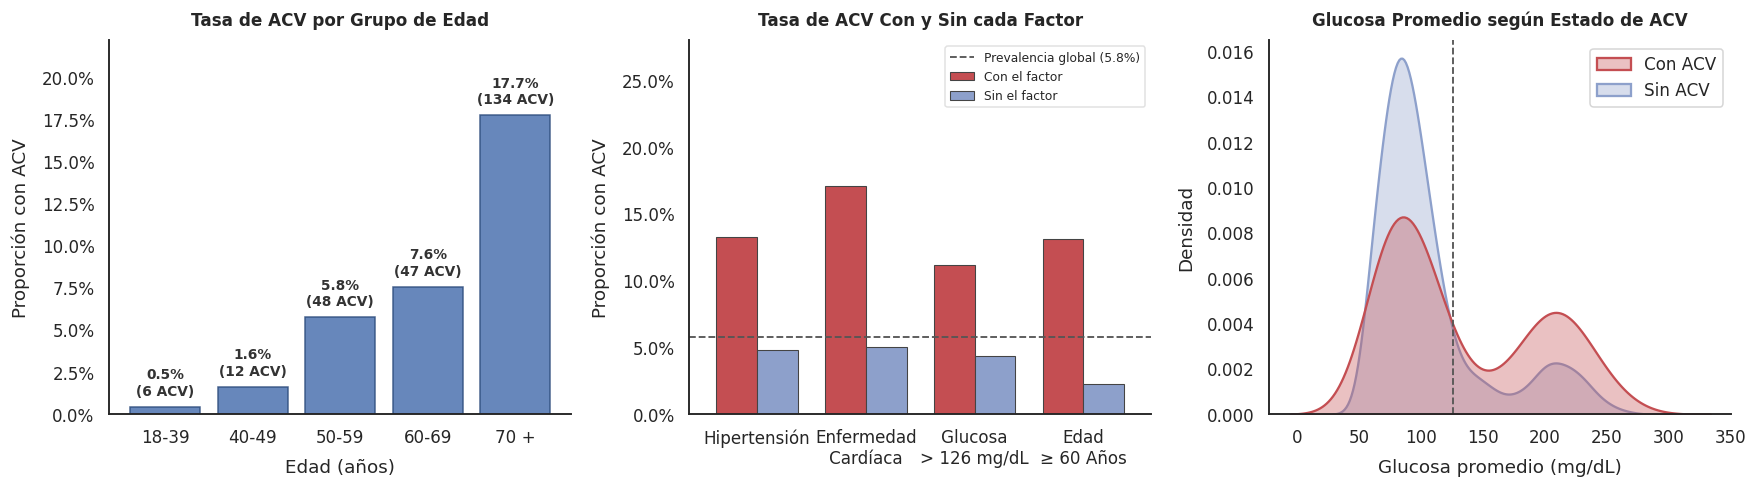

In [6]:
# 1. Configuración de la figura y estilo
sns.set_theme(style="white", palette="muted")
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), dpi=110)
prev = df["acv"].mean()

# (a) Tasa de ACV por grupo de edad
grupos_edad = pd.cut(df["edad"], [18, 40, 50, 60, 70, 121], right=False,
                     labels=["18-39", "40-49", "50-59", "60-69", "70 +"])
tasa_edad = df.groupby(grupos_edad, observed=True)["acv"].agg(["mean", "sum", "count"])

axes[0].bar(tasa_edad.index.astype(str), tasa_edad["mean"], color="#4C72B0", alpha=0.85, edgecolor="#2e4d7d")
for i, (m, s) in enumerate(zip(tasa_edad["mean"], tasa_edad["sum"])):
    axes[0].text(i, m + 0.005, f"{m:.1%}\n({s} ACV)", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#333333")

axes[0].set_title("Tasa de ACV por Grupo de Edad", fontweight="bold", fontsize=11, pad=10)
axes[0].set_xlabel("Edad (años)", labelpad=8)
axes[0].set_ylabel("Proporción con ACV", labelpad=8)
axes[0].set_ylim(0, tasa_edad["mean"].max() * 1.25)

# (b) Tasa de ACV según antecedentes y factores clave
condiciones = {
    "Hipertensión": df["hipertension"] == 1,
    "Enfermedad\nCardíaca": df["enfermedad_cardiaca"] == 1,
    "Glucosa\n> 126 mg/dL": df["nivel_glucosa_promedio"] > 126,
    "Edad\n≥ 60 Años": df["edad"] >= 60
}

filas = []
for k, m in condiciones.items():
    filas.append({
        "Factor": k,
        "Con el factor": df.loc[m, "acv"].mean(),
        "Sin el factor": df.loc[~m, "acv"].mean()
    })

pd.DataFrame(filas).set_index("Factor").plot.bar(ax=axes[1], color=["#C44E52", "#8DA0CB"], rot=0, width=0.75, edgecolor="#444444", linewidth=0.7)
axes[1].axhline(prev, color="#555555", ls="--", lw=1.2, label=f"Prevalencia global ({prev:.1%})")
axes[1].set_title("Tasa de ACV Con y Sin cada Factor", fontweight="bold", fontsize=11, pad=10)
axes[1].set_xlabel("", labelpad=8)
axes[1].set_ylabel("Proporción con ACV", labelpad=8)
# Aumentamos el límite superior de Y para dar espacio de aire a la leyenda superior
axes[1].set_ylim(0, 0.28)
# Ubicación óptima de la leyenda para evitar superposición con las barras de mayor altura (corregido alpha -> framealpha)
axes[1].legend(fontsize=8, frameon=True, facecolor="white", edgecolor="#e0e0e0", loc="upper right", framealpha=0.95)

# (c) Distribución de glucosa según ACV
sns.kdeplot(
    data=df, x="nivel_glucosa_promedio", hue=df["acv"].map({0: "Sin ACV", 1: "Con ACV"}),
    common_norm=False, fill=True, alpha=0.35, ax=axes[2],
    palette={"Sin ACV": "#8DA0CB", "Con ACV": "#C44E52"}, linewidth=1.5
)
axes[2].axvline(126, color="#555555", ls="--", lw=1.2)
axes[2].set_title("Glucosa Promedio según Estado de ACV", fontweight="bold", fontsize=11, pad=10)
axes[2].set_xlabel("Glucosa promedio (mg/dL)", labelpad=8)
axes[2].set_ylabel("Densidad", labelpad=8)
if axes[2].get_legend():
    axes[2].get_legend().set_title("")

# Formato porcentual para los ejes correspondientes
for ax in axes[:2]:
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

#### **Interpretación del Análisis Gráfico y Selección de Pruebas**

* **La Edad como Factor Crítico:** El gráfico (a) muestra que la tasa de ACV crece en cada tramo de edad: pasa del **0.5 % entre los 18 y 39 años** al **17.7 % en mayores de 70 años**. Más de 9 de cada 10 casos corresponden a personas de 50 años o más.
* **Fuerza de las Preexistencias Clínicas:** El gráfico (b) evidencia que contar con *Hipertensión*, *Enfermedad Cardíaca*, *Glucosa > 126 mg/dL* o *Edad ≥ 60 años* eleva la tasa de ACV muy por encima de la prevalencia general de los adultos (~5.8 %).
* **Distribución de Glucosa (Fuerte Asimetría):** El gráfico (c) muestra una distribución asimétrica, con una **segunda joroba** hacia valores altos que es mucho más marcada en las personas con ACV (compatible con diabetes mal controlada).
  * **Justificación de Test Estadístico:** Como las variables continuas no siguen una distribución normal, complementamos la prueba $t$ de Welch con la prueba no paramétrica **Mann-Whitney U** en el Paso 2.2, que compara rangos y no depende de ese supuesto.

### Paso 2.2: Contraste de Hipótesis Estadísticas

En este paso aplicamos pruebas cuantitativas formales para validar las diferencias observadas en las distribuciones. Calculamos el **Riesgo Relativo (RR)** con su intervalo de confianza del 95% para variables categóricas, y aplicamos los contrastes de hipótesis **t-Welch** y **Mann-Whitney U** para las variables continuas.

In [7]:
# ------------------------------------------------------------------------------
# 1. Función para Calcular Riesgo Relativo (RR), IC95% y Chi-Cuadrado
# ------------------------------------------------------------------------------
def razon_de_tasas(expuesto, y):
    a = y[expuesto].sum(); n1 = expuesto.sum()
    c = y[~expuesto].sum(); n0 = (~expuesto).sum()
    rr = (a / n1) / (c / n0)
    se = np.sqrt(1/a - 1/n1 + 1/c - 1/n0)
    lo, hi = np.exp(np.log(rr) - 1.96*se), np.exp(np.log(rr) + 1.96*se)
    chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(expuesto, y))
    return rr, lo, hi, p, a/n1, c/n0

# Target y filtro para tabaquismo
y_all = df["acv"]
fumo_conocido = df["fuma"] != "Desconocido"
todos = pd.Series(True, index=df.index)

# Definición de factores de riesgo con variables en español
factores = {
    "Edad ≥ 60": (df["edad"] >= 60, todos),
    "Enfermedad cardíaca": (df["enfermedad_cardiaca"] == 1, todos),
    "Hipertensión": (df["hipertension"] == 1, todos),
    "Glucosa > 126 mg/dL": (df["nivel_glucosa_promedio"] > 126, todos),
    "Fumó alguna vez (vs. Nunca)": (df["fuma"].isin(["Ex_fumador", "Fumador"]), fumo_conocido),
}

# Construcción de la tabla de Riesgos Relativos
filas_rr = []
for nombre, (mask, sub) in factores.items():
    rr, lo, hi, p, t1, t0 = razon_de_tasas(mask[sub].values, y_all[sub].values)
    filas_rr.append([nombre, t1, t0, rr, lo, hi, p])

tabla_rr = pd.DataFrame(
    filas_rr,
    columns=["Factor", "Tasa expuestos", "Tasa no expuestos", "RR", "IC95% inf", "IC95% sup", "p (chi2)"]
)
tabla_rr["¿p<0,05?"] = np.where(tabla_rr["p (chi2)"] < 0.05, "Sí", "No")

print("=== TABLA DE RIESGOS RELATIVOS Y CHI-CUADRADO ===")
display(tabla_rr)

# ------------------------------------------------------------------------------
# 2. Pruebas de Hipótesis para Variables Continuas (t-Welch y Mann-Whitney)
# ------------------------------------------------------------------------------
filas_num = []
variables_continuas = ["edad", "nivel_glucosa_promedio", "imc"]

for var in variables_continuas:
    g1 = df.loc[df["acv"] == 1, var].dropna()
    g0 = df.loc[df["acv"] == 0, var].dropna()

    t_p = stats.ttest_ind(g1, g0, equal_var=False).pvalue
    mw_p = stats.mannwhitneyu(g1, g0).pvalue

    filas_num.append([var, g1.mean(), g0.mean(), t_p, mw_p])

tabla_num = pd.DataFrame(
    filas_num,
    columns=["Variable", "Media con ACV", "Media sin ACV", "p t-Welch", "p Mann-Whitney"]
)
tabla_num["¿p<0,05?"] = np.where(tabla_num["p Mann-Whitney"] < 0.05, "Sí", "No")

print("\n=== COMPARACIÓN DE MEDIAS PARA VARIABLES NUMÉRICAS ===")
display(tabla_num)

=== TABLA DE RIESGOS RELATIVOS Y CHI-CUADRADO ===


,Factor,Tasa expuestos,Tasa no expuestos,RR,IC95% inf,IC95% sup,p (chi2),"¿p<0,05?"
0,Edad ≥ 60,0.132,0.023,5.734,4.358,7.545,0.000,Sí
1,Enfermedad cardíaca,0.171,0.050,3.399,2.535,4.558,0.000,Sí
2,Hipertensión,0.133,0.048,2.756,2.112,3.595,0.000,Sí
3,Glucosa > 126 mg/dL,0.112,0.044,2.563,2.010,3.269,0.000,Sí
4,Fumó alguna vez (vs. Nunca),0.068,0.051,1.330,1.016,1.741,0.044,Sí



=== COMPARACIÓN DE MEDIAS PARA VARIABLES NUMÉRICAS ===


,Variable,Media con ACV,Media sin ACV,p t-Welch,p Mann-Whitney,"¿p<0,05?"
0,edad,68.215,49.098,0.000,0.000,Sí
1,nivel_glucosa_promedio,133.099,106.990,0.000,0.000,Sí
2,imc,30.469,30.433,0.936,0.506,No


### <div align="center"><span style="font-size: 20px; font-weight: bold;"> Paso 2.3: Interpretación Clínica, Explicación del p-valor y Resumen de Hallazgos</span></div>

Tras ejecutar las pruebas estadísticas sobre la población adulta, analizamos los resultados para dar una base de justificación clínica al modelo predictivo.

---

#### 1. <span style="color:#2c3e50; font-weight:bold;">Interpretación de Resultados: Riesgo Relativo (RR)</span>
El **Riesgo Relativo (RR)** compara la tasa de ACV entre quienes tienen un factor y quienes no lo tienen:

* <span style="color:#e74c3c; font-weight:bold;">Edad ≥ 60 años (RR ≈ 5.73):</span> Es, por amplio margen, el factor más fuerte. Un adulto de 60 años o más tiene **unas 5.7 veces más probabilidad** de haber tenido un ACV que un adulto menor de 60 (IC 95 %: $[4.36, 7.55]$).
* <span style="color:#e67e22; font-weight:bold;">Enfermedad Cardíaca (RR ≈ 3.40):</span> Quienes tienen antecedentes cardiológicos presentan **unas 3.4 veces más probabilidad** de ACV (IC 95 %: $[2.54, 4.56]$).
* <span style="color:#e67e22; font-weight:bold;">Hipertensión (RR ≈ 2.76):</span> La hipertensión arterial se asocia con casi el **triple de probabilidad** de ACV (IC 95 %: $[2.11, 3.60]$).
* <span style="color:#2980b9; font-weight:bold;">Glucosa > 126 mg/dL (RR ≈ 2.56):</span> Superar el umbral diagnóstico de diabetes se asocia con **unas 2.6 veces más probabilidad** de ACV (IC 95 %: $[2.01, 3.27]$).
* <span style="color:#7f8c8d; font-weight:bold;">Historial de Tabaquismo (RR ≈ 1.33):</span> Haber fumado alguna vez se asocia con un **33 % más** de probabilidad de ACV, pero el extremo inferior del intervalo queda apenas por encima de 1 (IC 95 %: $[1.02, 1.74]$): es una asociación débil.

---

#### 2. <span style="color:#2c3e50; font-weight:bold;"> ¿Qué significa el p-valor en este análisis?</span>
El **p-valor** es la probabilidad de observar una diferencia **al menos tan grande** como la de nuestros datos **si en realidad no existiera ninguna relación** (hipótesis nula). No es la probabilidad de que el resultado «sea casualidad», sino una medida de cuán incompatibles son los datos con la ausencia de relación.

* **Nivel de Significación ($\alpha = 0.05$):** Si el p-valor es menor a $0.05$, rechazamos la hipótesis nula.
* **Resultados Categóricos:** Para *Edad*, *Hipertensión*, *Enfermedad Cardíaca* y *Glucosa* el p-valor es prácticamente cero ($p < 0.001$): sería muy improbable observar diferencias así si no hubiera asociación.
* **Tabaquismo ($p = 0.044$):** Es estadísticamente significativo, pero en el límite del umbral, en línea con su intervalo de confianza.
* **Pruebas Continuas (t-Welch y Mann-Whitney U):**
  * La **edad** (media de $68.2$ años con ACV vs. $49.1$ sin ACV) y la **glucosa promedio** ($133.1$ mg/dL vs. $107.0$) muestran diferencias altamente significativas ($p < 0.001$) en ambos tests.
  * El **IMC** (media de $30.47$ con ACV vs. $30.43$ sin ACV) **no presenta diferencias significativas** ($p = 0.936$ en Welch y $p = 0.506$ en Mann-Whitney). En el dataset completo sí aparecía asociado, pero era un efecto de la edad: los niños tienen IMC más bajo y casi no tienen ACV.

---

#### 3. <span style="color:#2c3e50; font-weight:bold;">Resumen Ejecutivo de Hallazgos Clínicos</span>
* **Sólido Fundamento para el Modelo:** Edad avanzada, hipertensión, enfermedad cardíaca e hiperglucemia tienen un RR claramente superior a $1.0$, con intervalos de confianza que no tocan la unidad.
* **Asociación no es causalidad:** Son comparaciones de a un factor por vez (univariadas) y no descuentan el efecto de la edad. Por eso conviene evaluar todas las variables juntas en un modelo multivariado, que estima cada efecto a igualdad de los demás (Sección 8).

# 3. Separación Train / Test (Holdout 20%)

Reservamos el **20 % estratificado** (manteniendo la misma proporción de ≈ 5.8 % de ACV en ambos conjuntos). Este *Test Set* se mantendrá aislado y se usará **una sola vez al final del proyecto**. Todo el entrenamiento, preprocesamiento y optimización de hiperparámetros se decidirá únicamente con *Train* para evitar la fuga de información (*Data Leakage*).

In [8]:
# Separación de características (X) y variable objetivo (y)
X = df.drop(columns=["acv"])
y = df["acv"]

# Partición estratificada 80% Train / 20% Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

# Reporte de estado de las particiones
print(f"Train: {X_train.shape[0]} filas, {y_train.sum()} ACV ({y_train.mean():.2%})")
print(f"Test:  {X_test.shape[0]} filas, {y_test.sum()} ACV ({y_test.mean():.2%})")

Train: 3402 filas, 198 ACV (5.82%)
Test:  851 filas, 49 ACV (5.76%)


####  Desglose de la Partición Realizada:
* **`X` e `y`:** Separamos los predictores clínicos (`X`) de la variable objetivo a predecir (`y = acv`).
* **`stratify=y`:** Asegura que la prevalencia de ACV sea prácticamente idéntica ($\sim 5.8\%$) en las $3.402$ filas de entrenamiento ($198$ ACV) y en las $851$ de prueba ($49$ ACV).
* **`random_state=SEED`:** Fija la semilla aleatoria para garantizar la reproducibilidad exacta de la partición en cualquier entorno.

# 4. Benchmark de Negocio: Regla Simple "Edad ≥ 60 o Hipertensión"

Esta es la vara o punto de comparación que los modelos de Machine Learning deben superar. Dado que la regla heurística no aprende parámetros de los datos, la evaluamos directamente tanto en el conjunto de entrenamiento (*Train*) como en el de prueba (*Test*).

> **Decisión de Diseño Metodológico:** Adoptamos el **PR-AUC (Área bajo la curva Precision-Recall)** como **métrica principal** de evaluación debido al severo desbalance de clases (~5.8 % de prevalencia). El **Recall (Sensibilidad)** queda definido como **objetivo operativo** para garantizar una cobertura clínica que capture la mayor cantidad de pacientes en riesgo.

#### Métricas de Evaluación Reportadas:
* **PR-AUC (Métrica Principal):** Resume la capacidad de **ordenar** a las personas por riesgo en todos los umbrales posibles. La regla solo dice «sí» o «no», así que su PR-AUC se calcula sobre dos valores y **no es directamente comparable** con el de un modelo que ordena: la informamos como referencia, pero la comparación justa con la regla se hace a igual esfuerzo y a igual Recall (§6.6 y §7).
* **Recall (Objetivo Operativo):** De todas las personas que sufrieron un ACV, ¿qué porcentaje capturamos como "alto riesgo"?
* **Precision:** De las personas marcadas como "alto riesgo", ¿qué porcentaje efectivamente tuvo un ACV? Representa la eficiencia del esfuerzo preventivo.
* **% Población Marcada:** Cuántas personas habría que intervenir/controlar. Representa el **costo operativo** para el sistema de salud.

In [9]:
# 1. Definición de la regla heurística simple adaptada a columnas en español
def regla(X):
    return ((X["edad"] >= 60) | (X["hipertension"] == 1)).astype(int).values

# 2. Función de evaluación operativa con PR-AUC como métrica principal
def metricas_binarias(y_true, y_pred, nombre):
    y_pred = np.asarray(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    auc_pr = average_precision_score(y_true, y_pred)
    return {
        "Criterio": nombre,
        "PR-AUC (Principal)": auc_pr,
        "Recall (Secundario)": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "% población marcada": y_pred.mean(),
        "VP": tp, "FP": fp, "FN": fn
    }

# 3. Cálculo de predicciones una única vez (reutilizables en futuras secciones)
regla_train, regla_test = regla(X_train), regla(X_test)
rec_regla_train = recall_score(y_train, regla_train)
pob_regla_train = regla_train.mean()

# 4. Construcción y renderizado de la tabla comparativa
tabla_benchmark = pd.DataFrame([
    metricas_binarias(y_train, np.zeros(len(y_train), int), "Sin modelo (nadie marcado) - train"),
    metricas_binarias(y_train, np.ones(len(y_train), int), "Marcar a todos - train"),
    metricas_binarias(y_train, regla_train, "Regla edad≥60 o HTA - train"),
    metricas_binarias(y_test, regla_test, "Regla edad≥60 o HTA - test"),
])

# Formatos porcentuales
FMT_BIN = {
    "PR-AUC (Principal)": "{:.3f}",
    "Recall (Secundario)": "{:.1%}",
    "Precision": "{:.1%}",
    "F1": "{:.3f}",
    "% población marcada": "{:.1%}"
}

display(tabla_benchmark.style.format(FMT_BIN).hide(axis="index"))

# 5. Narrativa operativa de negocio automatizada sobre el conjunto de Test
m = tabla_benchmark.iloc[3]
print(f"\n Reporte Operativo (Test Holdout): La regla cita al {m['% población marcada']:.1%} de la población y detecta "
      f"{m['VP']} de {m['VP']+m['FN']} ACVs reales (Recall: {m['Recall (Secundario)']:.1%}).")
print(f"   Precisión de {m['Precision']:.1%}: De cada 100 personas citadas de forma preventiva, solo ~{100*m['Precision']:.0f} tuvieron un ACV "
      f"real y ~{100*(1-m['Precision']):.0f} no ({m['FP']} falsos positivos en el sistema).")

Criterio,PR-AUC (Principal),Recall (Secundario),Precision,F1,% población marcada,VP,FP,FN
Sin modelo (nadie marcado) - train,0.058,0.0%,0.0%,0.000,0.0%,0,0,198
Marcar a todos - train,0.058,100.0%,5.8%,0.110,100.0%,198,3204,0
Regla edad≥60 o HTA - train,0.109,79.8%,12.2%,0.211,38.2%,158,1141,40
Regla edad≥60 o HTA - test,0.110,73.5%,12.9%,0.220,32.7%,36,242,13



 Reporte Operativo (Test Holdout): La regla cita al 32.7% de la población y detecta 36 de 49 ACVs reales (Recall: 73.5%).
   Precisión de 12.9%: De cada 100 personas citadas de forma preventiva, solo ~13 tuvieron un ACV real y ~87 no (242 falsos positivos en el sistema).


### Interpretación de Resultados del Benchmark Operativo

La tabla establece la línea de base operativa que nuestros modelos supervisados deberán superar:

1. **PR-AUC (Métrica Principal):**
   * La regla alcanza un **PR-AUC de $0.110$ en Test** (frente a $0.058$, que es lo que da no ordenar a nadie: la prevalencia). Por ser una regla binaria, este valor sirve como referencia, no como comparación directa con los modelos.

2. **Recall (Objetivo Operativo):**
   * La regla médica simple, que marca a quien cumple **al menos una** de las dos condiciones ($\text{edad} \ge 60$ **o** hipertensión), captura el **$73.5\%$ de los casos reales de ACV** en el conjunto de prueba (36 de los 49 pacientes con ACV).

3. **Variación entre Train y Test:**
   * El Recall pasa de $79.8\%$ en Train a $73.5\%$ en Test, y la población marcada de $38.2\%$ a $32.7\%$. Como la regla no se entrena, **no puede haber sobreajuste**: la diferencia se debe al azar de la partición (el test quedó con proporcionalmente menos personas de 60 años o más y con hipertensión). Con 49 casos, unos pocos pacientes mueven varios puntos porcentuales; por eso comparamos siempre modelo y regla **sobre las mismas personas**.

4. **Costo Operativo y Falsos Positivos:**
   * Para capturar ese $73.5\%$ de casos, la regla marca al **$32.7\%$ de la población de prueba** ($278$ pacientes de $851$). Esto genera **$242$ Falsos Positivos** y una **Precisión de $12.9\%$**: de cada 100 personas citadas, solo $\approx 13$ tuvieron un ACV y $\approx 87$ no.

> **Misión para el Modelado de Machine Learning:**
> Ordenar mejor a las personas por riesgo: que, **citando a la misma cantidad de gente**, encuentre más ACV, o que, **encontrando los mismos ACV**, cite a menos personas. Y que permita ajustar el punto de corte según los cupos disponibles, algo que una regla fija no permite.

# 5. Preprocesamiento Avanzado y Arquitectura de Pipeline

Construimos un `Pipeline` de preprocesamiento modular que encapsula la totalidad de las transformaciones de datos. Esto garantiza la regla de oro de Machine Learning: **ninguna estadística del conjunto de prueba o validación influye en las transformaciones de entrenamiento**, previniendo la **fuga de información (*Data Leakage*)**.

#### Componentes del Pipeline:
1. **`ImputadorIMC` (Custom Transformer):** Imputa los datos faltantes en la columna `imc` utilizando la **mediana por grupo de edad y género**. La tabla de medianas se aprende exclusivamente sobre el conjunto `Train`.
2. **`StandardScaler`:** Escala las variables continuas (`edad`, `nivel_glucosa_promedio`, `imc`) para la Regresión Logística, que es sensible a la magnitud de las variables (a los modelos de árboles no les afecta).
3. **`OneHotEncoder`:** Codifica las variables categóricas (`genero`, `casado`, `tipo_trabajo`, `tipo_residencia`, `fuma`) en columnas 0/1. Con `drop="first"` se omite una categoría por variable, que queda como referencia, y con `handle_unknown="ignore"` el pipeline no falla si una categoría muy poco frecuente (como `No_trabaja`, con 5 personas) no aparece en algún pliegue de entrenamiento.
4. **Passthrough:** Mantiene intactas las variables binarias clínicas ya codificadas (`hipertension`, `enfermedad_cardiaca`).

In [10]:
# ------------------------------------------------------------------------------
# 1. Transformador Personalizado para Imputación de IMC por Edad y Género
# ------------------------------------------------------------------------------
class ImputadorIMC(BaseEstimator, TransformerMixin):
    """Imputa el IMC faltante con la mediana por rango de edad y género (aprendida en fit)."""
    def __init__(self, bins=(0, 18, 40, 60, 120)):
        self.bins = bins

    def _grupo(self, X):
        rango_edad = pd.cut(X["edad"], bins=list(self.bins), right=False).astype(str)
        return rango_edad + "_" + X["genero"].astype(str)

    def fit(self, X, y=None):
        self.medianas_ = X["imc"].groupby(self._grupo(X)).median()
        self.global_ = X["imc"].median()
        return self

    def transform(self, X):
        X = X.copy()
        faltantes = X["imc"].isna()
        if faltantes.any():
            X.loc[faltantes, "imc"] = (self._grupo(X[faltantes]).map(self.medianas_)
                                       .fillna(self.global_).values)
        return X

# ------------------------------------------------------------------------------
# 2. Definición de Listas de Columnas Traducidas
# ------------------------------------------------------------------------------
num_cols = ["edad", "nivel_glucosa_promedio", "imc"]
bin_cols = ["hipertension", "enfermedad_cardiaca"]
cat_cols = ["genero", "casado", "tipo_trabajo", "tipo_residencia", "fuma"]

# ------------------------------------------------------------------------------
# 3. Función para Armar el Pipeline Completo con cualquier Modelo
# ------------------------------------------------------------------------------
def armar_pipeline(modelo, pasos_previos=()):
    preprocesador = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("bin", "passthrough", bin_cols),
        ("cat", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat_cols)])
    return Pipeline([("imputar_imc", ImputadorIMC()), *pasos_previos,
                     ("prep", preprocesador), ("modelo", modelo)])

# ------------------------------------------------------------------------------
# 4. Chequeo Rápido de Consistencia y Calidad en Test
# ------------------------------------------------------------------------------
chequeo = ImputadorIMC().fit(X_train).transform(X_test)
assert chequeo["imc"].isna().sum() == 0
assert (chequeo.loc[X_test["imc"].notna(), "imc"] == X_test.loc[X_test["imc"].notna(), "imc"]).all()
print("Pipeline definido. IMC imputados en test:", X_test["imc"].isna().sum(),
      "| nulos restantes:", chequeo["imc"].isna().sum())

Pipeline definido. IMC imputados en test: 38 | nulos restantes: 0


# 6. Modelado y Validación Cruzada Anidada ($5 \times 3$)

Con solo $\approx 200$ casos de ACV en el conjunto de entrenamiento, los modelos flexibles corren riesgo de sobreajustarse. Para garantizar una evaluación sin sesgos y controlar el *overfitting*, aplicamos cuatro estrategias clave:

1. **Tratamiento del Desbalance de Clases:** Usamos pesos de clase (`class_weight='balanced'` y `scale_pos_weight`) en lugar de SMOTE para evitar la invención de pacientes sintéticos que el modelo memorice.
2. **Espacios de Búsqueda Regularizados:** Acotamos la profundidad de los árboles (`max_depth`), fijamos un mínimo de muestras por hoja (`min_samples_leaf`) y aplicamos penalización $L2$.
3. **Validación Cruzada Anidada ($5 \times 3$):**
   * **Lazo interno (3 pliegues):** Selecciona los mejores hiperparámetros mediante `RandomizedSearchCV`.
   * **Lazo externo (5 pliegues):** Evalúa el rendimiento real del modelo en datos no vistos durante la búsqueda.
4. **Métrica de Búsqueda Principal (PR-AUC):** Optimizamos usando el área bajo la curva Precision-Recall (`average_precision`), adecuada para conjuntos con desbalance de clases severo ($\sim 5.8\%$).

---

### 6.1. Definición de Modelos Candidatos y Grillas de Búsqueda

In [11]:
# Cálculo del peso relativo de clases para XGBoost (≈ 16 negativos por cada positivo en adultos)
spw = (y_train == 0).sum() / (y_train == 1).sum()      # se imprime abajo

# Diccionario con los 3 modelos candidatos y sus rejillas de hiperparámetros
candidatos = {
    "Regresión Logística": (
        LogisticRegression(class_weight="balanced", max_iter=2000, random_state=SEED),
        {"modelo__C": loguniform(1e-3, 10)}),
    "Random Forest": (
        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                               random_state=SEED, n_jobs=-1),
        {"modelo__max_depth": [3, 4, 6, 8],
         "modelo__min_samples_leaf": [10, 20, 40, 80],
         "modelo__max_features": ["sqrt", 0.5]}),
    "XGBoost": (
        XGBClassifier(scale_pos_weight=spw, eval_metric="logloss", tree_method="hist",
                      random_state=SEED, n_jobs=2),
        {"modelo__n_estimators": [100, 200, 400],
         "modelo__max_depth": [2, 3, 4],
         "modelo__learning_rate": [0.01, 0.03, 0.1],
         "modelo__min_child_weight": [5, 10, 20],
         "modelo__subsample": [0.7, 0.9],
         "modelo__colsample_bytree": [0.7, 1.0],
         "modelo__reg_lambda": [1, 5, 20]})}

N_ITER = 15
cv_ext = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_int = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

def ajustar(nombre, version, X_fit, y_fit):
    """Entrena un candidato. 'Base' = hiperparámetros por defecto; 'Optimizada' = búsqueda interna."""
    modelo, grilla = candidatos[nombre]
    pipe = armar_pipeline(clone(modelo))
    if version == "Optimizada":
        return RandomizedSearchCV(pipe, grilla, n_iter=N_ITER, scoring="average_precision",
                                  cv=cv_int, random_state=SEED, n_jobs=-1).fit(X_fit, y_fit).best_estimator_
    return pipe.fit(X_fit, y_fit)

print(f"scale_pos_weight = {spw:.1f} | {len(candidatos)} algoritmos x 2 versiones | CV anidada 5 x 3")

scale_pos_weight = 16.2 | 3 algoritmos x 2 versiones | CV anidada 5 x 3


### 6.2. Ejecución del Lazo Anidado y Predicciones Out-Of-Fold (OOF)

Para cada uno de los 3 modelos candidatos evaluamos dos versiones:
* **Base:** Utiliza los hiperparámetros por defecto (ajustando únicamente los pesos de clase para tratar el desbalance).
* **Optimizada:** Ajusta sus hiperparámetros mediante `RandomizedSearchCV` en el lazo interno.

En cada pliegue externo guardamos las métricas de rendimiento (PR-AUC y ROC-AUC en validación, así como PR-AUC en entrenamiento para medir la brecha de sobreajuste) y las **probabilidades fuera de pliegue (*out-of-fold*, OOF)**.

>  **¿Qué son las predicciones OOF?** Son los scores asignados a cada paciente por un modelo que **no utilizó a ese paciente** durante su entrenamiento. Nos permiten analizar el desempeño en todo el rango de umbrales y **elegir el umbral de decisión operativo** sin tocar el conjunto de test.

 *Nota: La ejecución de la validación cruzada anidada para todas las combinaciones puede tomar un par de minutos.*

In [12]:
resultados = []
oof = {}
tiempos = {}

for nombre in candidatos:
    for version in ["Base", "Optimizada"]:
        t0 = time.time()
        prob_oof = np.zeros(len(y_train))
        for k, (tr, va) in enumerate(cv_ext.split(X_train, y_train)):
            Xtr, Xva = X_train.iloc[tr], X_train.iloc[va]
            ytr, yva = y_train.iloc[tr], y_train.iloc[va]

            # Se entrena usando la función helper que clona y arma el pipeline
            pipe = ajustar(nombre, version, Xtr, ytr)

            p_va = pipe.predict_proba(Xva)[:, 1]
            p_tr = pipe.predict_proba(Xtr)[:, 1]

            prob_oof[va] = p_va
            resultados.append({
                "Modelo": nombre,
                "Versión": version,
                "Pliegue": k,
                "PR-AUC val": average_precision_score(yva, p_va),
                "ROC-AUC val": roc_auc_score(yva, p_va),
                "PR-AUC train": average_precision_score(ytr, p_tr)
            })
        oof[(nombre, version)] = prob_oof
        tiempos[(nombre, version)] = time.time() - t0
        print(f"✔ {nombre} {version}: {tiempos[(nombre, version)]:.1f} s")

✔ Regresión Logística Base: 0.4 s
✔ Regresión Logística Optimizada: 16.6 s
✔ Random Forest Base: 9.4 s
✔ Random Forest Optimizada: 124.6 s
✔ XGBoost Base: 0.5 s
✔ XGBoost Optimizada: 21.4 s


### 6.3. Consolidación de Resultados y Tabla Comparativa

Una vez completada la validación cruzada anidada, consolidamos las métricas recolectadas en los 5 pliegues externos. Calculamos el promedio y la desviación estándar de **PR-AUC** y **ROC-AUC**, junto con la **Brecha de sobreajuste** ($
\text{PR-AUC}_{\text{train}} - \text{PR-AUC}_{\text{val}}$).

In [13]:
res = pd.DataFrame(resultados)
res["Brecha train-val"] = res["PR-AUC train"] - res["PR-AUC val"]

resumen_cv = (
    res.groupby(["Modelo", "Versión"])
    .agg(
        PR_AUC_val=("PR-AUC val", "mean"),
        PR_AUC_desvio=("PR-AUC val", "std"),
        ROC_AUC_val=("ROC-AUC val", "mean"),
        PR_AUC_train=("PR-AUC train", "mean"),
        Brecha=("Brecha train-val", "mean")
    )
    .sort_values("PR_AUC_val", ascending=False)
)
resumen_cv["Tiempo (s)"] = [tiempos[i] for i in resumen_cv.index]

display(resumen_cv.style.format({c: "{:.3f}" for c in resumen_cv.columns} | {"Tiempo (s)": "{:.1f}"}))

mejor_val, peor_val = resumen_cv["PR_AUC_val"].max(), resumen_cv["PR_AUC_val"].min()
print(f"\n Lectura: el PR-AUC de validación va de {peor_val:.3f} a {mejor_val:.3f} "
      f"(azar ≈ {y_train.mean():.3f}); el desvío entre pliegues es de {resumen_cv['PR_AUC_desvio'].min():.3f} "
      f"a {resumen_cv['PR_AUC_desvio'].max():.3f}.")

for (mod, ver), fila in resumen_cv.iterrows():
    if fila["Brecha"] > 0.5:
        print(f"  {mod} {ver}: PR-AUC train {fila['PR_AUC_train']:.3f} vs. validación {fila['PR_AUC_val']:.3f} → memoriza el entrenamiento.")


 Lectura: el PR-AUC de validación va de 0.153 a 0.196 (azar ≈ 0.058); el desvío entre pliegues es de 0.014 a 0.031.
  XGBoost Base: PR-AUC train 1.000 vs. validación 0.182 → memoriza el entrenamiento.
  Random Forest Base: PR-AUC train 1.000 vs. validación 0.153 → memoriza el entrenamiento.


### **Interpretación de Resultados y Control de Sobreajuste**

Al examinar la tabla comparativa (`resumen_cv`), destacamos:

1. **Rendimiento Relativo de los Algoritmos:**
   * La **Regresión Logística** encabeza el benchmark, tanto en su versión *Optimizada* ($\text{PR-AUC}_{\text{val}} = 0.196$) como en su versión *Base* ($0.194$), muy por encima del azar ($\approx 0.058$).
   * **Random Forest optimizado** queda muy cerca ($\approx 0.191$): la optimización lo mejoró notablemente respecto de su versión base ($\approx 0.153$).
   * En cambio, **XGBoost no mejoró al optimizarlo** (base $\approx 0.182$, optimizado $\approx 0.175$): con tan pocos casos, la búsqueda de hiperparámetros no siempre encuentra un mejor resultado que los valores por defecto.

2. **Diagnóstico de Sobreajuste (Brecha Train vs. Validación):**
   * **Modelos Base de Árboles (RF y XGBoost):** Memorizan por completo el conjunto de entrenamiento ($\text{PR-AUC}_{\text{train}} = 1.000$), con brechas severas de sobreajuste de $0.818$ (XGBoost) y $0.847$ (Random Forest).
   * **Árboles optimizados:** La regularización reduce la brecha, aunque siguen reteniendo cierto grado de memorización (brechas de $0.160$ en RF y $0.325$ en XGBoost).
   * **Regresión Logística:** Brecha prácticamente nula en ambas versiones ($-0.003$ y $-0.000$): rinde igual en entrenamiento que en validación, lo que confirma una excelente capacidad de generalización con pocos casos positivos.

3. **Eficiencia Computacional y Escalabilidad:**
   * La **Regresión Logística Optimizada** requirió apenas **16.6 segundos** para completar la búsqueda de hiperparámetros y validación cruzada ($k=5$), frente a los **124.6 segundos** de Random Forest Optimizado y **21.4 segundos** de XGBoost Optimizado.
   * La versión **Base de Regresión Logística** entrenó en solo **0.4 segundos** manteniendo prácticamente la misma capacidad discriminativa ($\text{PR-AUC}_{\text{val}} = 0.194$). Esto demuestra que

### 6.4. Visualización del Desempeño y Comparación Estadística

Para complementar el análisis numérico, graficamos el desempeño de los modelos en validación cruzada ($5 \times 3$), incorporando las barras de error (desviación estándar entre pliegues) y la línea base del azar ($\approx 5.8\%$).

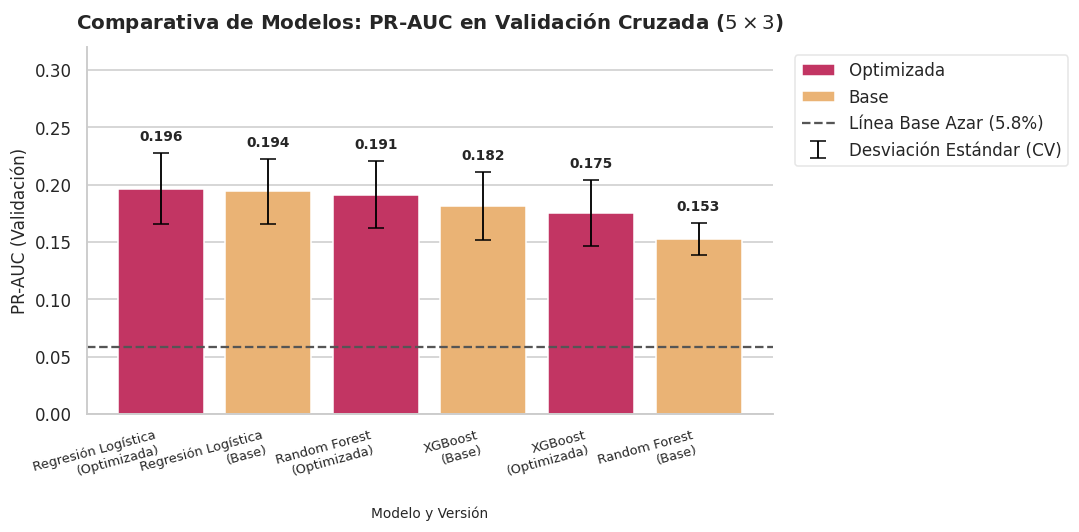

In [14]:
# Estilo visual moderno con Seaborn
sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(10, 5), dpi=110)

# Preparación de datos para el gráfico
orden = resumen_cv.reset_index()
orden["Modelo_Version"] = orden["Modelo"] + "\n(" + orden["Versión"] + ")"

# Gráfico de barras principal para PR-AUC en Validación
sns.barplot(
    data=orden,
    x="Modelo_Version",
    y="PR_AUC_val",
    hue="Versión",
    dodge=False,
    palette={"Base": "#FDB462", "Optimizada": "#D91E5B"},
    ax=ax
)

# Superponemos las barras de error manualmente basadas en la desviación estándar
ax.errorbar(
    x=np.arange(len(orden)),
    y=orden["PR_AUC_val"],
    yerr=orden["PR_AUC_desvio"],
    fmt="none",
    c="black",
    capsize=5,
    linewidth=1.2,
    label="Desviación Estándar (CV)"
)

# Línea de referencia del azar / prevalencia de entrenamiento (~5.8%)
prevalencia = y_train.mean()
ax.axhline(
    prevalencia,
    color="#555555",
    linestyle="--",
    linewidth=1.5,
    label=f"Línea Base Azar ({prevalencia:.1%})"
)

# Configuración de etiquetas y título
ax.set_title("Comparativa de Modelos: PR-AUC en Validación Cruzada ($5 \\times 3$)", fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("Modelo y Versión", fontsize=9, labelpad=12)
ax.set_ylabel("PR-AUC (Validación)", fontsize=11)
ax.set_ylim(0, 0.32)

# Solución definitiva al solapamiento: Rotación en diagonal (15 grados) y alineación horizontal a la derecha
ax.set_xticklabels(orden["Modelo_Version"], rotation=15, ha="right", fontsize=8.5)

# Anotación de valores exactos sobre cada barra
for i, row in orden.iterrows():
    ax.text(
        i, row["PR_AUC_val"] + row["PR_AUC_desvio"] + 0.008,
        f"{row['PR_AUC_val']:.3f}",
        ha="center", va="bottom", fontsize=9, fontweight="bold"
    )

# Colocar la leyenda fuera del gráfico para evitar solapamientos
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, facecolor="white", edgecolor="#e0e0e0")

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

#### **Análisis Visual y Comparación Estadística de Intervalos**

* **Superación del Piso Aleatorio:**
  * Todas las variantes superan la línea de referencia del **azar (~5.8 %)**. No obstante, el PR-AUC máximo alcanzado (~0.196, unas 3.4 veces el azar) indica que el fenómeno tiene un techo de predictibilidad bajo con estas variables. Por lo tanto, el modelo final debe concebirse como una **herramienta de triaje y priorización** de recursos preventivos, y no como un sistema de diagnóstico.
* **Memorización en Modelos Base de Árboles (Overfitting):**
  * *Random Forest Base* y *XGBoost Base* (en **naranja suave**) memorizan por completo el conjunto de entrenamiento (**PR-AUC de 1.000**), pero en validación caen a **≈ 0.15 y ≈ 0.18**. Los modelos de árboles tienden a sobreajustar con pocos eventos si no se los regulariza.
* **Estabilidad de la Regresión Logística:**
  * La **Regresión Logística** tiene una brecha entre entrenamiento y validación prácticamente nula y el rendimiento medio de validación más alto (**PR-AUC = 0.196** en su versión optimizada, en **carmín**).
* **Incertidumbre y Solapamiento:**
  * Las barras de error muestran desvíos de hasta $\approx \pm 0.03$ entre pliegues, explicados por el reducido número de casos positivos en cada pliegue de validación ($\approx 40$ ACV). Las barras de la Regresión Logística (ambas versiones), Random Forest optimizado y XGBoost base se superponen.
  * **Conclusión:** Al no haber diferencias claras entre la Regresión Logística y los modelos más complejos, se aplica el **Principio de Parsimonia**: se selecciona la Regresión Logística por su bajo costo, su robustez frente al sobreajuste y su interpretabilidad clínica mediante *Odds Ratios*.

### 6.5. Selección Automática del Modelo Candidato (Criterio de Parsimonia)

Para elegir el algoritmo definitivo, aplicamos una regla de decisión basada en el **Principio de Parsimonia (Navaja de Occam)**, fijada antes de ver los resultados para evitar elegir modelos complejos sin justificación:

1. **Identificación del Ganador Absoluto:** Seleccionamos el modelo y versión con el mayor valor medio de **PR-AUC en validación cruzada** ($\text{PR-AUC}_{val}$).
2. **Evaluación de Parsimonia:** Si el ganador absoluto es un modelo complejo (*XGBoost* o *Random Forest*), lo comparamos contra la mejor versión de la **Regresión Logística**.
3. **Regla de Tolerancia Estadística:** Si la diferencia de rendimiento entre ambos es **menor a una desviación estándar del modelo ganador** (es decir, $\Delta \text{PR-AUC} < \sigma_{ganador}$), aplicamos parsimonia y **seleccionamos la Regresión Logística**.

> **Justificación Clínica y Operativa:** Las diferencias dentro de una desviación estándar se atribuyen al ruido del muestreo y no a una superioridad predictiva sistemática. En salud, preferir un modelo lineal en ese escenario aporta robustez frente al sobreajuste, interpretabilidad mediante *Odds Ratios* y una implementación computacional muy liviana.

In [15]:
# =============================================================================
# SELECCIÓN AUTOMÁTICA DE MODELO CANDIDATO (CRITERIO DE PARSIMONIA)
# =============================================================================

# 1. Asegurar el ordenamiento correcto de la tabla de resultados
resumen_ordenado = resumen_cv.sort_values("PR_AUC_val", ascending=False)

# 2. Identificar el mejor modelo absoluto (primera fila)
mejor_combinacion = resumen_ordenado.index[0] # Tupla (Modelo, Versión)
mejor_modelo, mejor_version = mejor_combinacion

auc_mejor = resumen_ordenado.loc[mejor_combinacion, "PR_AUC_val"]
desvio_mejor = resumen_ordenado.loc[mejor_combinacion, "PR_AUC_desvio"]

# 3. Extraer la mejor versión de la Regresión Logística de manera robusta
rl_rows = resumen_ordenado.xs("Regresión Logística", level="Modelo", drop_level=False)
mejor_rl_combinacion = rl_rows.index[0]  # La primera fila de RL en la tabla ordenada
mejor_rl_ver = mejor_rl_combinacion[1]
auc_rl = resumen_ordenado.loc[mejor_rl_combinacion, "PR_AUC_val"]

# 4. Calcular diferencia de rendimiento
diferencia_rendimiento = auc_mejor - auc_rl

# 5. Aplicar Criterio de Parsimonia
if mejor_modelo != "Regresión Logística" and diferencia_rendimiento < desvio_mejor:
    elegido = mejor_rl_combinacion
    motivo = (
        f"Aunque el mejor modelo absoluto es {mejor_modelo} ({mejor_version}) con PR-AUC = {auc_mejor:.3f}, "
        f"la Regresión Logística ({mejor_rl_ver}) queda a solo {diferencia_rendimiento:.3f} de distancia. "
        f"Al ser esta diferencia menor que 1 desviación estándar del ganador (σ = {desvio_mejor:.3f}), "
        f"se aplica el Principio de Parsimonia en favor de la simplicidad y la interpretabilidad clínica."
    )
else:
    elegido = mejor_combinacion
    if mejor_modelo == "Regresión Logística":
        motivo = f"La Regresión Logística ({mejor_version}) es el líder indiscutido del benchmark con el mayor PR-AUC promedio ({auc_mejor:.3f})."
    else:
        motivo = (
            f"Se selecciona {mejor_modelo} ({mejor_version}) debido a que supera a la Regresión Logística "
            f"por una diferencia de {diferencia_rendimiento:.3f}, la cual excede el umbral de tolerancia estadística de la desviación estándar (σ = {desvio_mejor:.3f})."
        )

# Guardar el modelo elegido en el estado global para celdas subsiguientes
elegido_modelo, elegido_version = elegido

print("=============================================================================")
print(" RESULTADO DE LA SELECCIÓN AUTOMÁTICA DEL MODELO")
print("=============================================================================")
print(f"• Ganador Absoluto: {mejor_modelo} ({mejor_version}) | PR-AUC: {auc_mejor:.3f} (± {desvio_mejor:.3f})")
print(f"• Mejor Regresión Logística: {mejor_rl_combinacion[0]} ({mejor_rl_combinacion[1]}) | PR-AUC: {auc_rl:.3f}")
print(f"• Diferencia Calculada: {diferencia_rendimiento:.4f}")
print("-----------------------------------------------------------------------------")
print(f" MODELO SELECCIONADO FINAL: {elegido_modelo} ({elegido_version})")
print(f" MOTIVO: {motivo}")
print("=============================================================================")

 RESULTADO DE LA SELECCIÓN AUTOMÁTICA DEL MODELO
• Ganador Absoluto: Regresión Logística (Optimizada) | PR-AUC: 0.196 (± 0.031)
• Mejor Regresión Logística: Regresión Logística (Optimizada) | PR-AUC: 0.196
• Diferencia Calculada: 0.0000
-----------------------------------------------------------------------------
 MODELO SELECCIONADO FINAL: Regresión Logística (Optimizada)
 MOTIVO: La Regresión Logística (Optimizada) es el líder indiscutido del benchmark con el mayor PR-AUC promedio (0.196).


In [16]:
# Inspeccionamos detalladamente el rendimiento del benchmark para Regresión Logística
display(resumen_cv.loc[["Regresión Logística"]])

PR_AUC_val  PR_AUC_desvio  ROC_AUC_val  \
Modelo              Versión                                              
Regresión Logística Optimizada       0.196          0.031        0.813   
                    Base             0.194          0.028        0.812   

                                PR_AUC_train  Brecha  Tiempo (s)  
Modelo              Versión                                       
Regresión Logística Optimizada         0.193  -0.003      16.582  
                    Base               0.194  -0.000       0.415

### 6.6. Elección del Umbral de Decisión (vía OOF)

El **PR-AUC** evalúa la capacidad de ordenar del modelo integrando todos los umbrales posibles (por eso es la métrica para elegir el algoritmo). Pero la **operación clínica real** exige fijar un único punto de corte: a partir de qué score se cita a la persona.

####  Por qué no usar el umbral estándar ($0.50$)
* **El 0.50 no tiene un significado especial en este modelo:** al entrenar con pesos de clase balanceados, los scores quedan «inflados» respecto de la probabilidad real (la prevalencia es de apenas $\approx 5.8\%$), y los umbrales útiles resultan entre $\approx 0.45$ y $0.60$.
* **El corte debe responder a un criterio de negocio:** un umbral elegido sin criterio puede dejar sin detectar a muchos casos (si es alto) o saturar las agendas (si es bajo).

####  Metodología de Selección basada en Probabilidades Out-Of-Fold (OOF)
Analizamos el balance entre **Precisión**, **Recall (Sensibilidad)** y **F1-Score** a lo largo de todos los umbrales posibles. El umbral que maximiza F1 se muestra solo como referencia; nuestro criterio es el KPI operativo: **el umbral más alto que logra Recall ≥ 60 %**. Además calculamos dos umbrales para comparar contra la regla en igualdad de condiciones (mismo esfuerzo y mismo Recall).

Todo se calcula exclusivamente sobre las **probabilidades fuera de pliegue (OOF)** del modelo seleccionado (Regresión Logística Optimizada), de modo que el umbral se elige con datos que el modelo no vio durante su entrenamiento y sin tocar el conjunto de test.

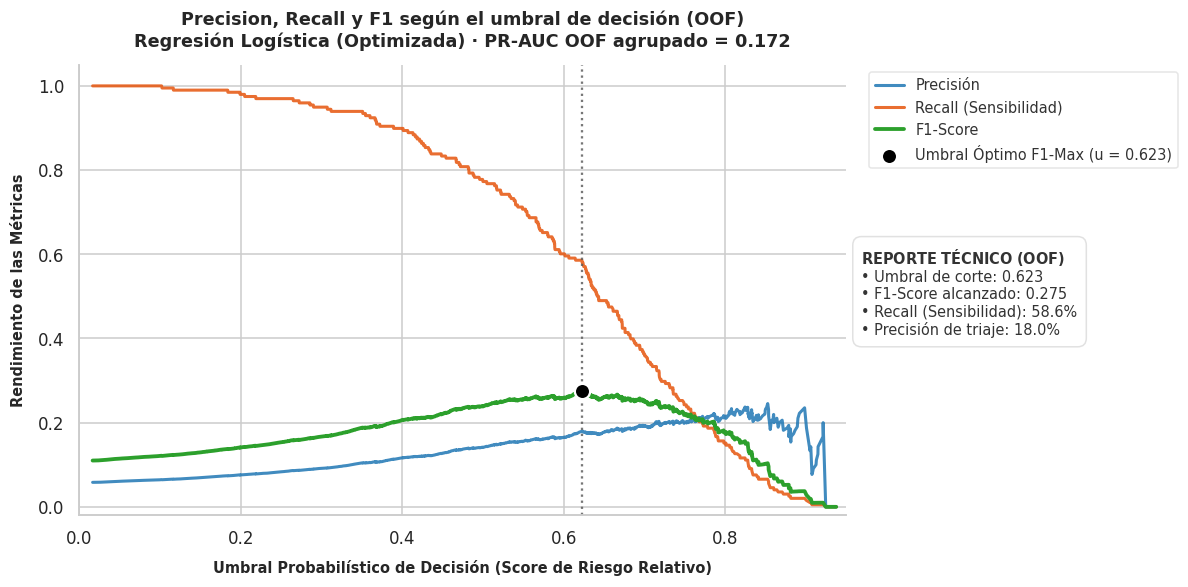

In [17]:
# 0. Configuración tipográfica global para forzar la misma fuente en leyenda y cuadro de texto
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']

# 1. Extracción de probabilidades OOF y cálculo de métricas continuas
y_prob_oof = oof[elegido]
precisions, recalls, thresholds = precision_recall_curve(y_train, y_prob_oof)

# Evitar división por cero en el cálculo del F1-Score
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1] + 1e-10)

# Determinar el umbral óptimo basado en el máximo F1-Score
n_positive = y_train.sum()
idx_opt = np.argmax(f1_scores)
u_opt = thresholds[idx_opt]
f1_opt = f1_scores[idx_opt]
prec_opt = precisions[idx_opt]
rec_opt = recalls[idx_opt]

# 2. Configuración estética de estilo y diseño minimalista
sns.set_theme(style="whitegrid", palette="muted")
fig, ax = plt.subplots(figsize=(11, 5.5), dpi=110)

# Dibujo de curvas continuas de rendimiento con colores suaves y elegantes
ax.plot(thresholds, precisions[:-1], label="Precisión", color="#1f77b4", linewidth=2, alpha=0.85)
ax.plot(thresholds, recalls[:-1], label="Recall (Sensibilidad)", color="#e6550d", linewidth=2, alpha=0.85)
ax.plot(thresholds, f1_scores, label="F1-Score", color="#2ca02c", linewidth=2.5, alpha=1.0)

# Resaltar el umbral óptimo con una línea vertical integrada y un marcador destacado
ax.axvline(u_opt, color="#555555", linestyle=":", linewidth=1.5, alpha=0.8)
ax.scatter([u_opt], [f1_opt], color="black", s=100, zorder=10, edgecolors="white", linewidths=1.5,
           label=f"Umbral Óptimo F1-Max (u = {u_opt:.3f})")

# Cuadro de texto técnico en formato lateral externo similar a una leyenda
# El título se formatea en negrita usando mathtext de Matplotlib ($\mathbf{...}$)
info_texto = (
    r"$\mathbf{REPORTE\ TÉCNICO\ (OOF)}$" + "\n"
    f"• Umbral de corte: {u_opt:.3f}\n"
    f"• F1-Score alcanzado: {f1_opt:.3f}\n"
    f"• Recall (Sensibilidad): {rec_opt:.1%}\n"
    f"• Precisión de triaje: {prec_opt:.1%}"
)

# Posicionamiento lateral por fuera del gráfico usando tipografía y color alineados a la leyenda
ax.text(
    1.02, 0.4,
    info_texto, transform=ax.transAxes,
    fontsize=9.5,
    fontfamily="sans-serif",
    color="#333333",
    fontweight="normal",
    bbox=dict(boxstyle="round,pad=0.6", fc="white", ec="#e0e0e0", lw=1, alpha=0.95)
)

# Configuración de ejes y límites limpios
ax.set_title(f"Precision, Recall y F1 según el umbral de decisión (OOF)\n{elegido[0]} ({elegido[1]}) · PR-AUC OOF agrupado = {average_precision_score(y_train, y_prob_oof):.3f}", fontsize=11.5, fontweight="bold", pad=12)
ax.set_xlabel("Umbral Probabilístico de Decisión (Score de Riesgo Relativo)", fontsize=9.5, fontweight="bold", labelpad=8)
ax.set_ylabel("Rendimiento de las Métricas", fontsize=9.5, fontweight="bold", labelpad=8)
ax.set_xlim(0, 0.95)
ax.set_ylim(-0.02, 1.05)

# Ubicar la leyenda de manera clara en el lateral por fuera del gráfico con tipografía idéntica
ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=True,
    facecolor="white",
    edgecolor="#e0e0e0",
    fontsize=9.5,
    labelcolor="#333333"
)

sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

#### **Cuadro Comparativo de Umbrales Operativos**
A continuación se muestran los valores exactos de **Precisión**, **Recall** y **F1-Score** evaluados en los tres escenarios clave de decisión clínica:

In [18]:
# 1. Función para hallar el umbral más alto que garantiza un Recall objetivo
def umbral_para_recall(y_true, y_prob, objetivo):
    umbrales_posibles = np.sort(np.unique(y_prob))[::-1]
    for t in umbrales_posibles:
        if recall_score(y_true, (y_prob >= t).astype(int)) >= objetivo:
            return t
    return 0.5

# 2. Extracción de probabilidades OOF del modelo elegido y parámetros de la Regla
y_prob_oof = oof[elegido]
rec_regla_train = recall_score(y_train, regla_train)
pob_regla_train = regla_train.mean()

# 3. Definición de los 3 umbrales operativos
u_operativo = umbral_para_recall(y_train, y_prob_oof, 0.60)
u_mismo_esfuerzo = np.quantile(y_prob_oof, 1 - pob_regla_train)
u_mismo_recall = umbral_para_recall(y_train, y_prob_oof, rec_regla_train)

umbrales = {
    "Operativo (Recall ≥ 60%)": u_operativo,
    "Mismo esfuerzo que la regla": u_mismo_esfuerzo,
    "Mismo Recall que la regla": u_mismo_recall
}

# 4. Función de métricas binarias unificada para la tabla comparativa
def metricas_binarias_tabla(y_true, y_pred, nombre):
    y_pred = np.asarray(y_pred)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {
        "Criterio": nombre,
        "Recall": recall_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "% población marcada": y_pred.mean(),
        "VP": tp, "FP": fp, "FN": fn
    }

# 5. Construcción de filas (Regla + 3 Variaciones del Modelo)
filas = [metricas_binarias_tabla(y_train, regla_train, "Regla edad≥60 o HTA")]
for nombre_u, u in umbrales.items():
    filas.append(metricas_binarias_tabla(y_train, (y_prob_oof >= u).astype(int), f"Modelo · {nombre_u}") | {"Umbral": u})

tabla_umbrales_oof = pd.DataFrame(filas)[["Criterio", "Umbral", "Recall", "Precision", "F1",
                                           "% población marcada", "VP", "FP", "FN"]]

# Mostrar tabla con formato del benchmark
display(tabla_umbrales_oof.style.format(FMT_BIN | {"Recall": "{:.1%}", "Umbral": "{:.3f}"}, na_rep="—").hide(axis="index"))

# 6. Reporte narrativo de negocio automatizado para entrenamiento
r, op, es, re_ = [tabla_umbrales_oof.iloc[i] for i in range(4)]
print("\n Lectura (train, predicciones OOF):")
print(f"   • Umbral operativo: Recall {op['Recall']:.1%} citando al {op['% población marcada']:.1%} "
      f"de la población (la regla cita al {r['% población marcada']:.1%}). Precision {op['Precision']:.1%} vs. {r['Precision']:.1%}.")
print(f"   • A igual esfuerzo ({es['% población marcada']:.1%} de la población): el modelo encuentra {es['VP']} ACV "
      f"y la regla {r['VP']} (Recall {es['Recall']:.1%} vs. {r['Recall']:.1%}).")
print(f"   • A igual Recall ({re_['Recall']:.1%}): el modelo cita al {re_['% población marcada']:.1%} y la regla "
      f"al {r['% población marcada']:.1%} → {int(r['FP']-re_['FP'])} falsos positivos menos sobre {len(y_train)} personas.")

Criterio,Umbral,Recall,Precision,F1,% población marcada,VP,FP,FN
Regla edad≥60 o HTA,—,79.8%,12.2%,0.211,38.2%,158,1141,40
Modelo · Operativo (Recall ≥ 60%),0.601,60.1%,16.6%,0.260,21.1%,119,599,79
Modelo · Mismo esfuerzo que la regla,0.449,83.3%,12.7%,0.220,38.2%,165,1134,33
Modelo · Mismo Recall que la regla,0.483,79.8%,13.9%,0.236,33.5%,158,982,40



 Lectura (train, predicciones OOF):
   • Umbral operativo: Recall 60.1% citando al 21.1% de la población (la regla cita al 38.2%). Precision 16.6% vs. 12.2%.
   • A igual esfuerzo (38.2% de la población): el modelo encuentra 165 ACV y la regla 158 (Recall 83.3% vs. 79.8%).
   • A igual Recall (79.8%): el modelo cita al 33.5% y la regla al 38.2% → 159 falsos positivos menos sobre 3402 personas.


#### **Justificación de Umbrales Operativos y Comparación de Negocio desde una Perspectiva Clínica**

Elegir los puntos de corte con las predicciones **Out-Of-Fold (OOF)** permite simular el comportamiento del modelo frente a pacientes nuevos sin usar el conjunto de test (evitando el sesgo de optimismo y la fuga de información). Son resultados de **validación**: se confirman, o no, en la Sección 7.

Analizamos tres escenarios operativos frente a la regla tradicional:

---

● **Umbral Clínico Operativo (Recall Objetivo $\ge 60\%$)**
* **Configuración Técnica:** Umbral de decisión **$u = 0.601$**.
* **Rendimiento OOF:** Logra un **Recall del $60.1\%$** (119 de 198 pacientes con ACV) citando al **$21.1\%$ de la población** ($718$ pacientes), contra el $38.2\%$ que cita la regla.
* **Fundamento de Negocio:** Es una estrategia para programas con recursos muy limitados: concentra la intervención en una quinta parte de la población. La **Precisión sube al $16.6\%$** (contra el $12.2\%$ de la regla, un aumento relativo de ≈ 36 %), a cambio de detectar menos casos que la regla.

● **Umbral de Mismo Esfuerzo Operativo (Costo de Intervención Equivalente)**
* **Configuración Técnica:** Umbral **$u = 0.449$**, que marca exactamente al **$38.2\%$ de la población**, el mismo esfuerzo de citación que la regla.
* **Rendimiento OOF:** El **Recall** sube al **$83.3\%$** ($165$ casos) contra el $79.8\%$ de la regla ($158$ casos).
* **Fundamento de Negocio:** Con el mismo presupuesto y personal ($1.299$ citaciones), el modelo encuentra **7 casos más** en validación. Es una ventaja moderada, que hay que confirmar en test.

● **Umbral de Mismo Recall (Misma Cobertura, Menor Costo)**
* **Configuración Técnica:** Umbral **$u = 0.483$**, que iguala el Recall de la regla (**$79.8\%$**).
* **Rendimiento OOF:** Captura los mismos $158$ casos citando al **$33.5\%$ de la población** ($1.140$ pacientes) en lugar del $38.2\%$.
* **Fundamento de Negocio:** Es el escenario de eficiencia más directa: se evitan **159 citaciones de personas sin ACV** (falsos positivos) en el conjunto de entrenamiento, liberando turnos y estudios complementarios sin perder casos detectados.

>  **Nota Clínica sobre la Interpretación de Scores:**
>
> Al entrenar el modelo con pesos de clase balanceados (`class_weight='balanced'`), la escala de los scores se desplaza hacia arriba para penalizar más la omisión de casos positivos. Por lo tanto, deben interpretarse como un **score de riesgo relativo para ordenar y priorizar pacientes**, y no como la probabilidad real de tener un ACV.
>
> * **Para Triaje y Priorización (uso actual):** Los scores sin calibrar son adecuados, porque preservan el ordenamiento (*ranking*) de los pacientes de mayor a menor riesgo.
> * **Para comunicar un riesgo individual:** Si en el futuro se necesitara que el score refleje la probabilidad real en la población (≈ 5.8 % en adultos de este dataset), habría que recalibrarlo a posteriori (calibración isotónica o de Platt, mediante `CalibratedClassifierCV`).

### 6.7. Evaluaciones Complementarias de Negocio: Curvas PR y Ganancia Acumulada OOF

Antes de la evaluación definitiva en test, analizamos las probabilidades **Out-of-Fold (OOF)** desde dos ángulos que traducen las métricas en valor clínico y de gestión:

* **Curva Precision-Recall vs. Regla Simple:**
  Comparamos la Regresión Logística con la regla «edad ≥ 60 o hipertensión» (punto negro). Si la curva del modelo pasa **por encima** del punto, significa que a igual Recall el modelo logra más Precisión, es decir, menos falsos positivos.

* **Curva de Ganancia Acumulada (*Cumulative Gain*):**
  Responde a la pregunta de negocio: *«Si concentramos los controles en el X % de pacientes con mayor score, ¿qué porcentaje de los ACV logramos captar?»*.
  * **KPI de Focalización:** priorizando al **40 % de mayor score**, el modelo captura el **83.8 % de los ACV** en validación, por encima de la meta de ≥ 70 %. Con el top 30 % captura el 76.3 % (≈ 2.5 veces lo que daría elegir al azar).

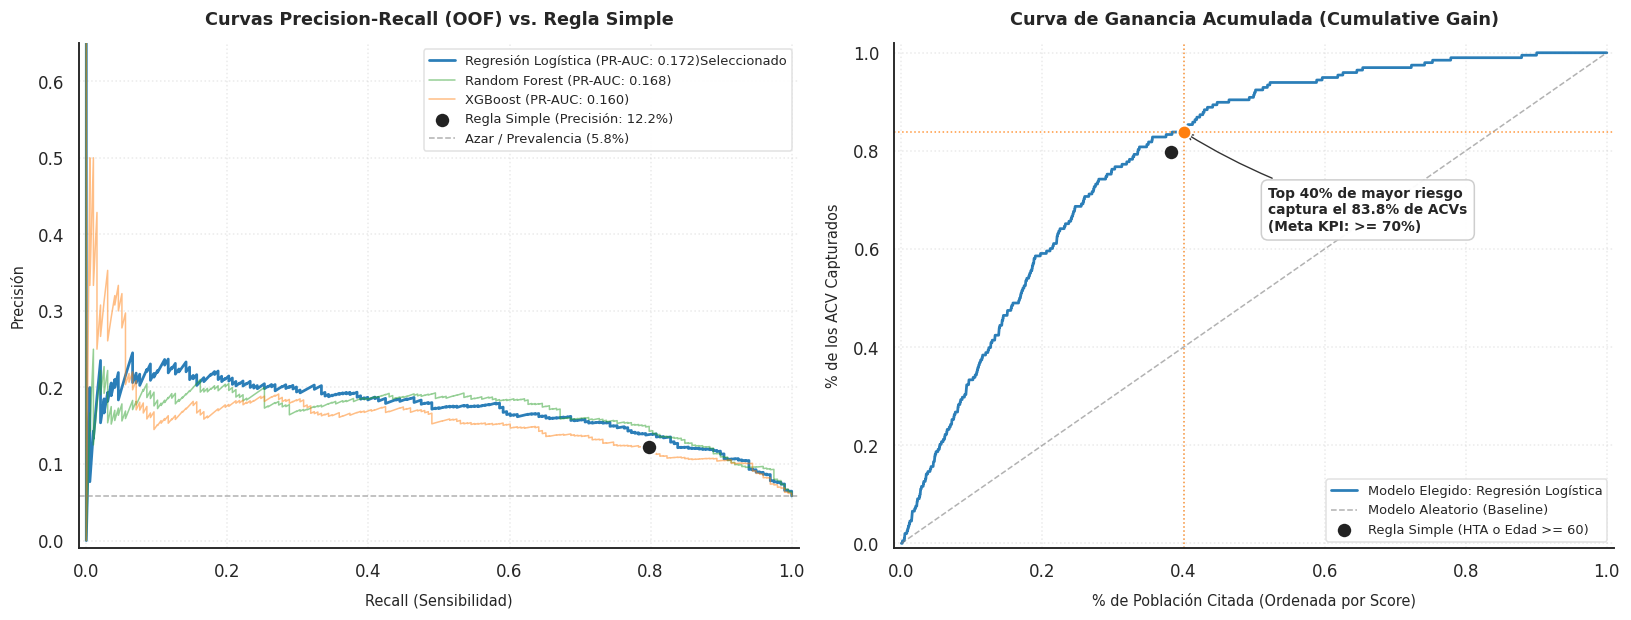

In [19]:
# 1. Función para captura del Top (Ganancia Acumulada)
def captura_top(y_true, y_prob, frac):
    """Proporción de los ACV que queda dentro del 'frac' de personas con mayor score."""
    y_true, y_prob = np.asarray(y_true), np.asarray(y_prob)
    k = int(np.ceil(frac * len(y_prob)))
    top = np.argsort(-y_prob, kind="stable")[:k]
    return y_true[top].sum() / y_true.sum()

# Extraemos la precisión exacta de la regla simple en entrenamiento para el gráfico
prec_regla_train = precision_score(y_train, regla_train)

# 2. Configuración estética general y paleta firme de alta resolución
sns.set_theme(style="white", palette="muted")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), dpi=110)

# Paleta sólida de colores firmes
colores_modelos = {
    "Regresión Logística": "#1f77b4",  # Azul corporativo firme
    "Random Forest": "#2ca02c",        # Verde clínico firme
    "XGBoost": "#ff7f0e"               # Naranja firme
}

# =============================================================================
# SUBGRÁFICO 1: Curvas Precision-Recall (Limpias, Suaves y Profesionales)
# =============================================================================
for nombre in candidatos:
    prob_oof = oof[(nombre, "Optimizada")]
    prec, rec, _ = precision_recall_curve(y_train, prob_oof)
    ap = average_precision_score(y_train, prob_oof)

    es_elegido = nombre == elegido_modelo

    axes[0].plot(
        rec, prec,
        color=colores_modelos[nombre],
        linewidth=1.8 if es_elegido else 1.0,
        alpha=0.95 if es_elegido else 0.50,
        antialiased=True,
        label=f"{nombre} (PR-AUC: {ap:.3f}){'Seleccionado' if es_elegido else ''}"
    )

# Marcador limpio de la Regla Simple tradicional
axes[0].scatter(
    [rec_regla_train], [prec_regla_train],
    color="#222222", s=100, zorder=6, edgecolors="white", linewidths=1.2,
    label=f"Regla Simple (Precisión: {prec_regla_train:.1%})"
)

# Línea base del azar / prevalencia
axes[0].axhline(
    np.mean(y_train), color="#7f7f7f", linestyle="--", linewidth=1.0, alpha=0.6,
    label=f"Azar / Prevalencia ({np.mean(y_train):.1%})"
)

# Estilizado fino de ejes
axes[0].set_title("Curvas Precision-Recall (OOF) vs. Regla Simple", fontsize=11.5, fontweight="bold", pad=12)
axes[0].set_xlabel("Recall (Sensibilidad)", fontsize=9.5, labelpad=8)
axes[0].set_ylabel("Precisión", fontsize=9.5, labelpad=8)
axes[0].set_xlim(-0.01, 1.01)
axes[0].set_ylim(-0.01, 0.65)
axes[0].grid(True, linestyle=":", alpha=0.4, color="#cccccc")
axes[0].legend(loc="upper right", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#e0e0e0", framealpha=0.95)

# =============================================================================
# SUBGRÁFICO 2: Curva de Ganancia Acumulada (Cumulative Gain)
# =============================================================================
# Aseguramos arrays NumPy para evitar inconsistencias de indexación
y_true_arr = np.asarray(y_train)
y_prob_arr = np.asarray(y_prob_oof)

# Ordenamiento estable por score descendente
orden_score = np.argsort(-y_prob_arr, kind="stable")

# Calculamos la ganancia y la población acumulada
gan = np.cumsum(y_true_arr[orden_score]) / y_true_arr.sum()
pob = np.arange(1, len(gan) + 1) / len(gan)

# CORRECCIÓN CLAVE: Incluir el origen (0, 0)
gan = np.insert(gan, 0, 0.0)
pob = np.insert(pob, 0, 0.0)

# Línea del Modelo Elegido
axes[1].plot(
    pob, gan,
    color=colores_modelos.get(elegido_modelo, "#1f77b4"), linewidth=1.8, alpha=0.95, antialiased=True,
    label=f"Modelo Elegido: {elegido_modelo}"
)

# Diagonal de referencia aleatoria
axes[1].plot(
    [0, 1], [0, 1],
    color="#7f7f7f", linestyle="--", linewidth=1.0, alpha=0.6,
    label="Modelo Aleatorio (Baseline)"
)

# Marcador destacado para la Regla Simple
axes[1].scatter(
    [pob_regla_train], [rec_regla_train],
    color="#222222", s=100, zorder=6, edgecolors="white", linewidths=1.2,
    label="Regla Simple (HTA o Edad >= 60)"
)

# Punto clave en el Top 40% (KPI de Focalización de Salud)
g40 = captura_top(y_train, y_prob_oof, 0.40)
axes[1].scatter([0.40], [g40], color="#ff7f0e", s=80, zorder=6, edgecolors="white", linewidths=1.2)

# Guías visuales punteadas para el KPI del Top 40%
axes[1].axhline(g40, color="#ff7f0e", linestyle=":", linewidth=1.0, alpha=0.8)
axes[1].axvline(0.40, color="#ff7f0e", linestyle=":", linewidth=1.0, alpha=0.8)

# Anotación técnica del KPI en el Top 40%
axes[1].annotate(
    f"Top 40% de mayor riesgo\ncaptura el {g40:.1%} de ACVs\n(Meta KPI: >= 70%)",
    xy=(0.40, g40),
    xytext=(0.52, g40 - 0.20),
    arrowprops=dict(arrowstyle="->", color="#333333", lw=0.9, connectionstyle="arc3,rad=-0.08"),
    fontsize=9, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.5", fc="white", ec="#cccccc", lw=1, alpha=0.95)
)

# Estilizado fino de ejes
axes[1].set_title("Curva de Ganancia Acumulada (Cumulative Gain)", fontsize=11.5, fontweight="bold", pad=12)
axes[1].set_xlabel("% de Población Citada (Ordenada por Score)", fontsize=9.5, labelpad=8)
axes[1].set_ylabel("% de los ACV Capturados", fontsize=9.5, labelpad=8)
axes[1].set_xlim(-0.01, 1.01)
axes[1].set_ylim(-0.01, 1.02)
axes[1].grid(True, linestyle=":", alpha=0.4, color="#cccccc")
axes[1].legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white", edgecolor="#e0e0e0", framealpha=0.95)

# Ajustes y renderizado final
sns.despine(top=True, right=True)
plt.tight_layout()
plt.show()

#### **Análisis de Impacto Clínico y Priorización de Negocio (OOF)**

1. **Eficiencia del Triaje (Curva PR):**
   * El punto negro representa la **Regla Simple**. La curva de la **Regresión Logística Optimizada** (línea azul gruesa) pasa **levemente por encima** de ese punto: a igual Recall, el modelo logra algo más de Precisión. La ventaja es **moderada**, porque la regla ya usa las dos señales más fuertes (edad e hipertensión). Las curvas de los tres algoritmos son casi indistinguibles en la zona de Recall alto, lo que refuerza la elección del modelo más simple.

2. **Cumplimiento del KPI de Focalización (Top 40 %):**
   * Concentrar los controles preventivos en el **40 % de pacientes con mayor score** permite identificar al **$83.8\%$ de los casos de ACV** en validación, por encima de la meta de ≥ 70 %.
   * Con menos cupos, el **Top 30 %** captura el **$76.3\%$** de los casos (≈ 2.5 veces lo que se obtendría citando al azar).

3. **Optimización bajo Presupuesto Fijo (Mismo Esfuerzo Operativo):**
   * Citando al mismo **$38.2\%$** de la población que la regla, el modelo detecta al **$83.3\%$ de los casos** contra el **$79.8\%$** de la regla.
   * Es una **ganancia de +3.5 puntos porcentuales** (7 casos) en validación, sin aumentar el esfuerzo. Hay que confirmarla en el conjunto de test (Sección 7).

# 7. Evaluación Definitiva sobre el Conjunto de Test (Holdout)

El conjunto de reserva (**20 % Holdout**) se mantuvo aislado y no participó de ninguna fase de preprocesamiento, entrenamiento o elección de umbrales. En esta sección realizamos la validación final:

1. **Re-entrenamiento final**: El modelo seleccionado (**Regresión Logística Optimizada**) se entrena con la totalidad de los datos de entrenamiento (`X_train`, `y_train`).
2. **Evaluación Operativa**: Se aplican sobre el test los umbrales fijados en la sección 6.6 (sin recalcularlos).
3. **Comparación de Desempeño**: Se compara el modelo con la Regla Simple mediante métricas de clasificación y matrices de confusión.
4. **Bootstrap (2.000 réplicas)**: Se mide la incertidumbre estadística de las diferencias, reconociendo la alta variabilidad dada la muestra limitada del test (49 casos de ACV).
5. **Verificación de KPI**: Se evalúa el cumplimiento de la meta de focalización en datos nuevos.

### 7.1. Evaluación Puntual y Matrices de Confusión Comparativas

Evaluamos el modelo aplicando sobre el Test Set los umbrales determinados previamente con las predicciones OOF de entrenamiento:
* **Umbral Operativo ($u_{operativo} = 0.601$)** (Recall objetivo $\ge 60\%$)
* **Mismo Esfuerzo ($u_{esfuerzo} = 0.449$)** (misma población intervenida que la regla simple en entrenamiento)
* **Mismo Recall ($u_{recall} = 0.483$)** (misma tasa de captura de casos que la regla simple en entrenamiento)

COMPARATIVA DE MÉTRICAS CONTINUAS DE ÁREA (TEST VS VALIDACIÓN)
PR-AUC test: 0.229   (validación: 0.196 ± 0.031 promedio de pliegues · 0.172 OOF agrupado · azar: 0.058)
ROC-AUC test: 0.809   (validación: 0.813 promedio de pliegues)

Métricas en TEST (umbrales fijados en train):


Criterio,Umbral,Recall (Secundario),Precision,F1,% población marcada,VP,FP,FN
Regla edad≥60 o HTA,-,73.5%,12.9%,0.220,32.7%,36,242,13
Modelo - Operativo (Recall ≥ 60%),0.601,57.1%,15.7%,0.247,20.9%,28,150,21
Modelo - Mismo esfuerzo que la regla,0.449,73.5%,13.5%,0.228,31.4%,36,231,13
Modelo - Mismo Recall que la regla,0.483,71.4%,14.2%,0.236,29.0%,35,212,14


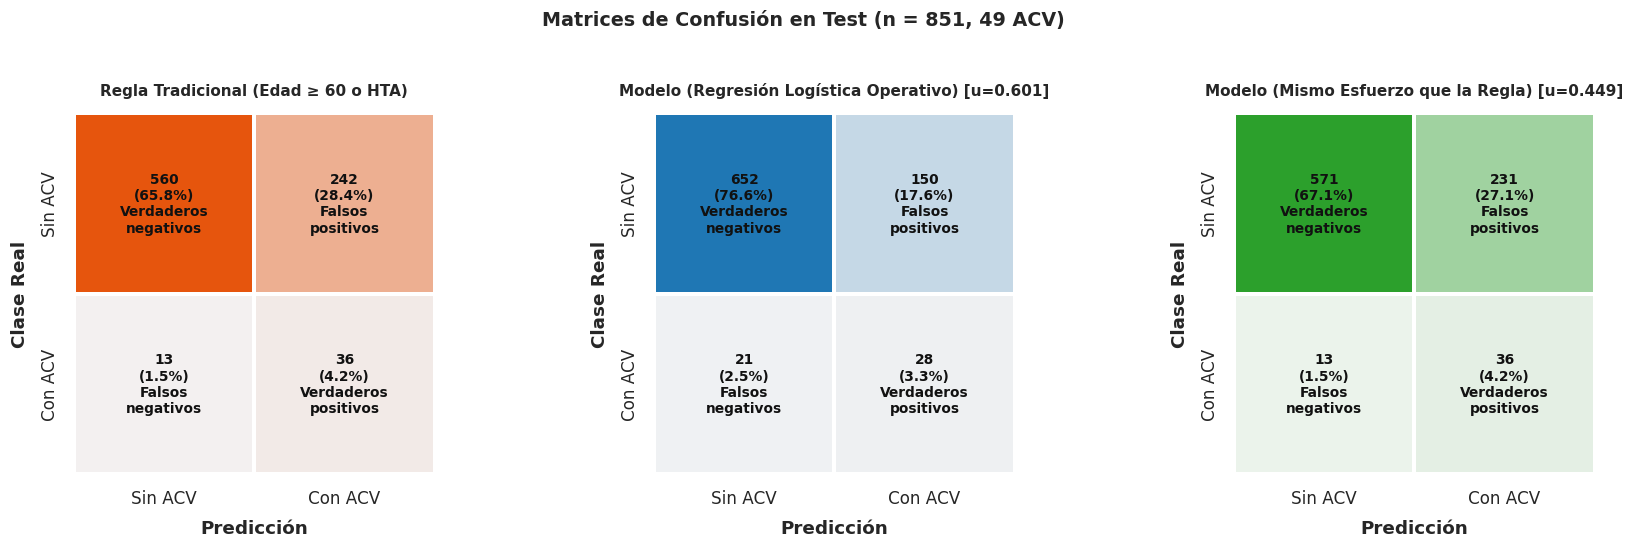

In [20]:
# 1. Ajustar el pipeline final con todos los datos de Train y predecir en Test
modelo_final = ajustar(elegido[0], elegido[1], X_train, y_train)
y_prob_test = modelo_final.predict_proba(X_test)[:, 1]

# 2. Reporte de Métricas Continuas comparadas con Validación Cruzada
pr_auc_test = average_precision_score(y_test, y_prob_test)
roc_auc_test = roc_auc_score(y_test, y_prob_test)
pr_auc_cv, pr_auc_cv_sd = resumen_cv.loc[elegido, ["PR_AUC_val", "PR_AUC_desvio"]]
pr_auc_oof = average_precision_score(y_train, y_prob_oof)

print("=" * 60)
print("COMPARATIVA DE MÉTRICAS CONTINUAS DE ÁREA (TEST VS VALIDACIÓN)")
print("=" * 60)
print(f"PR-AUC test: {pr_auc_test:.3f}   (validación: {pr_auc_cv:.3f} ± {pr_auc_cv_sd:.3f} promedio de pliegues · {pr_auc_oof:.3f} OOF agrupado · azar: {y_test.mean():.3f})")
print(f"ROC-AUC test: {roc_auc_test:.3f}   (validación: {resumen_cv.loc[elegido, 'ROC_AUC_val']:.3f} promedio de pliegues)\n")

# 3. Predicciones discretas y construcción de la tabla de Test
pred_test = {n: (y_prob_test >= u).astype(int) for n, u in umbrales.items()}

f_regla = metricas_binarias(y_test, regla_test, "Regla edad≥60 o HTA")
f_regla['Umbral'] = np.nan  # Usamos NaN para que Pandas aplique correctamente na_rep="-"
filas = [f_regla]

for nombre_u, u in umbrales.items():
    f_mod = metricas_binarias(y_test, pred_test[nombre_u], f"Modelo - {nombre_u}")
    f_mod['Umbral'] = u
    filas.append(f_mod)

tabla_test = pd.DataFrame(filas)[["Criterio", "Umbral", "Recall (Secundario)", "Precision", "F1", "% población marcada", "VP", "FP", "FN"]]

print("Métricas en TEST (umbrales fijados en train):")
# Formateamos 'Umbral' de forma aislada sin forzar 'str'
fmt_dic = {col: fmt for col, fmt in FMT_BIN.items() if col in tabla_test.columns}
fmt_dic["Umbral"] = "{:.3f}"

display(tabla_test.style.format(fmt_dic, na_rep="-").hide(axis="index"))

# 4. Visualización de los 3 Paneles de Matrices de Confusión
y_pred_op = pred_test["Operativo (Recall ≥ 60%)"]
y_pred_es = pred_test["Mismo esfuerzo que la regla"]

paneles = [
    ("Regla Tradicional (Edad ≥ 60 o HTA)", regla_test, "#e6550d"),
    (f"Modelo (Regresión Logística Operativo) [u={umbrales['Operativo (Recall ≥ 60%)']:.3f}]", y_pred_op, "#1f77b4"),
    (f"Modelo (Mismo Esfuerzo que la Regla) [u={umbrales['Mismo esfuerzo que la regla']:.3f}]", y_pred_es, "#2ca02c")
]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), dpi=110)

labels_ejes = ["Sin ACV", "Con ACV"]

etiquetas = [
    ["Verdaderos\nnegativos", "Falsos\npositivos"],
    ["Falsos\nnegativos", "Verdaderos\npositivos"]
]

for ax, (titulo, pred, color) in zip(axes, paneles):
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(
        cm,
        annot=False,
        cmap=sns.light_palette(color, as_cmap=True),
        cbar=False,
        ax=ax,
        linewidths=2.5,
        linecolor="white",
        square=True,
        xticklabels=labels_ejes,
        yticklabels=labels_ejes
    )

    for i in range(2):
        for j in range(2):
            val = cm[i, j]
            pct = (val / len(y_test)) * 100
            texto_celda = f"{val}\n({pct:.1f}%)\n{etiquetas[i][j]}"

            ax.text(
                j + 0.5, i + 0.5, texto_celda,
                ha="center", va="center", fontsize=9, fontweight="bold", color="#111111"
            )

    ax.set_title(titulo, fontsize=10, fontweight="bold", pad=12)
    ax.set_xlabel("Predicción", fontweight="bold", labelpad=8)
    ax.set_ylabel("Clase Real", fontweight="bold", labelpad=8)

plt.suptitle(f"Matrices de Confusión en Test (n = {len(y_test):,}, {y_test.sum()} ACV)", fontweight="bold", fontsize=12.5, y=1.03)
plt.tight_layout()
plt.show()

#### **Análisis del Impacto Clínico y Operativo en el Conjunto de Test (Holdout)**

Las matrices de confusión sobre el conjunto de **Test (n = 851 adultos, 49 ACV)** permiten contrastar las estrategias con la regla tradicional:

* **1. Regla Simple Tradicional (Línea de Base):**
  * **Comportamiento:** Cita a **278 pacientes (32.7 % de la muestra)** y detecta **36 de los 49 ACV** (Recall: **73.5 %**).
  * **Costo Operativo:** Genera **242 Falsos Positivos**: un **87.1 %** de las personas citadas no tuvo un ACV.

* **2. Modelo con Umbral Operativo ($u = 0.601$):**
  * **Comportamiento:** Cita a **178 pacientes (20.9 % de la muestra)** y detecta **28 ACV** (Recall: **57.1 %**). **No alcanza la meta de Recall ≥ 60 %** en datos nuevos: el umbral se fijó para lograr justo 60 % en entrenamiento y no dejó margen.
  * **Impacto Clínico:** Reduce los Falsos Positivos un **38 %** (de 242 a 150), pero detecta **8 casos menos** que la regla. La precisión sube de 12.9 % a **15.7 %** (≈ 1.2 veces). Es un punto de trabajo para cuando los cupos son muy escasos, no una mejora sin costo.

* **3. Modelo con Mismo Esfuerzo ($u = 0.449$):**
  * **Comportamiento:** Cita al **31.4 % de la muestra** y captura **36 de los 49 ACV** (Recall: **73.5 %**), **los mismos casos que la regla**, con 11 falsos positivos menos (231 contra 242).

* **4. Modelo con Mismo Recall ($u = 0.483$):**
  * **Comportamiento:** Cita al **29.0 % de la muestra** y detecta **35 ACV** (Recall: **71.4 %**), con 212 falsos positivos.

> **En síntesis:** en datos nuevos el modelo **no detecta más casos que la regla** a igual esfuerzo; su aporte está en **citar a menos personas** para un resultado similar. El bootstrap de la sección 7.2 indica cuáles de estas diferencias son estadísticamente significativas.

### 7.2. Cuantificación de la Incertidumbre Estadística mediante Bootstrap Pareado (IC 95%)

Dado el tamaño acotado de eventos de ACV en el conjunto de Test ($n = 49$ casos), las métricas puntuales pueden fluctuar por el azar del muestreo. Para medir cuánta confianza merecen las diferencias entre el modelo y la regla, aplicamos un **Bootstrap Pareado (con 2.000 réplicas)**.

#### ¿Cómo funciona este análisis?
1. **Remuestreo con Reposición**: Generamos $2.000$ conjuntos de evaluación alternativos seleccionando aleatoriamente pacientes del set de Test original con reposición.
2. **Evaluación Pareada**: En cada réplica, el modelo y la regla simple se evalúan **sobre los mismos pacientes remuestreados**. Esto permite calcular directamente la diferencia de rendimiento:
   $$\Delta = \text{Métrica}_{\text{Modelo}} - \text{Métrica}_{\text{Regla}}$$
3. **Criterio de Significación**: Si el intervalo de confianza (IC 95 %) del $\Delta$ no incluye el valor $0$, la diferencia es estadísticamente significativa (con $\alpha = 0.05$), sea a favor o en contra del modelo.
4. **Comparación Libre de Umbrales (Top-k Mismo Esfuerzo)**: Para no depender de trasladar umbrales fijados en Train, en cada réplica contamos cuántas personas cita la regla ($k$), hacemos que el modelo cite a sus $k$ pacientes de mayor score y comparamos cuántos ACV encuentra cada uno.

In [21]:
# 1. Asegurar formato de arrays NumPy de las variables de test
yt = np.asarray(y_test)
p_test = np.asarray(y_prob_test)
p_regla = np.asarray(regla_test)
p_op, p_es, p_re = (np.asarray(pred_test[n]) for n in umbrales)

def recall_topk(y, prob, k):
    return y[np.argsort(-prob, kind="stable")[:k]].sum() / y.sum()

def comparar(y, prob, regla_, op_, es_, re_):
    """Todas las métricas de una muestra (la original o una réplica bootstrap)."""
    rec = lambda pred: recall_score(y, pred)
    pre = lambda pred: precision_score(y, pred, zero_division=0)
    return {"PR-AUC modelo": average_precision_score(y, prob),
            "ROC-AUC modelo": roc_auc_score(y, prob),
            "Recall modelo (umbral operativo)": rec(op_),
            "Precision modelo (umbral operativo)": pre(op_),
            "Δ Recall · mismas personas citadas (top-k)": recall_topk(y, prob, int(regla_.sum())) - rec(regla_),
            "Δ Recall · umbral mismo esfuerzo": rec(es_) - rec(regla_),
            "Δ Precision · umbral mismo esfuerzo": pre(es_) - pre(regla_),
            "Δ % población · umbral mismo Recall": re_.mean() - regla_.mean(),
            "Δ Recall · umbral mismo Recall": rec(re_) - rec(regla_),
            "Δ % población · umbral operativo": op_.mean() - regla_.mean(),
            "Δ Recall · umbral operativo": rec(op_) - rec(regla_),
            "Δ Precision · umbral operativo": pre(op_) - pre(regla_)}

puntual = comparar(yt, p_test, p_regla, p_op, p_es, p_re)

B = 2000
rng = np.random.default_rng(SEED)
replicas = []
for _ in range(B):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].sum() == 0:
        continue
    replicas.append(comparar(yt[idx], p_test[idx], p_regla[idx], p_op[idx], p_es[idx], p_re[idx]))
boot = pd.DataFrame(replicas)

tabla_boot = pd.DataFrame({"Puntual": pd.Series(puntual),
                           "IC 95% inf": boot.quantile(0.025),
                           "IC 95% sup": boot.quantile(0.975)})

es_delta = tabla_boot.index.str.startswith("Δ")
tabla_boot["¿IC excluye 0?"] = np.where(~es_delta, "—",
        np.where((tabla_boot["IC 95% inf"] > 0) | (tabla_boot["IC 95% sup"] < 0), "Sí", "No"))

print(f"Bootstrap pareado sobre test · {len(boot)} réplicas válidas")
display(tabla_boot.style.format("{:.3f}", subset=["Puntual", "IC 95% inf", "IC 95% sup"]))

print(" Lectura:")
for k in ["PR-AUC modelo", "Δ Recall · mismas personas citadas (top-k)", "Δ % población · umbral mismo Recall",
          "Δ % población · umbral operativo", "Δ Recall · umbral operativo", "Δ Precision · umbral operativo"]:
    f = tabla_boot.loc[k]
    extra = "" if f["¿IC excluye 0?"] == "—" else ("  → diferencia significativa" if f["¿IC excluye 0?"] == "Sí"
                                                    else "  → NO se puede descartar que sea azar")
    print(f"   • {k}: {f['Puntual']:+.3f}  IC 95% [{f['IC 95% inf']:+.3f}; {f['IC 95% sup']:+.3f}]{extra}")

Bootstrap pareado sobre test · 2000 réplicas válidas


,Puntual,IC 95% inf,IC 95% sup,¿IC excluye 0?
PR-AUC modelo,0.229,0.145,0.343,—
ROC-AUC modelo,0.809,0.754,0.861,—
Recall modelo (umbral operativo),0.571,0.429,0.706,—
Precision modelo (umbral operativo),0.157,0.105,0.212,—
Δ Recall · mismas personas citadas (top-k),0.000,-0.056,0.073,No
Δ Recall · umbral mismo esfuerzo,0.000,-0.063,0.056,No
Δ Precision · umbral mismo esfuerzo,0.005,-0.007,0.017,No
Δ % población · umbral mismo Recall,-0.036,-0.055,-0.019,Sí
Δ Recall · umbral mismo Recall,-0.020,-0.095,0.045,No
Δ % población · umbral operativo,-0.118,-0.141,-0.095,Sí


 Lectura:
   • PR-AUC modelo: +0.229  IC 95% [+0.145; +0.343]
   • Δ Recall · mismas personas citadas (top-k): +0.000  IC 95% [-0.056; +0.073]  → NO se puede descartar que sea azar
   • Δ % población · umbral mismo Recall: -0.036  IC 95% [-0.055; -0.019]  → diferencia significativa
   • Δ % población · umbral operativo: -0.118  IC 95% [-0.141; -0.095]  → diferencia significativa
   • Δ Recall · umbral operativo: -0.163  IC 95% [-0.283; -0.055]  → diferencia significativa
   • Δ Precision · umbral operativo: +0.028  IC 95% [-0.003; +0.058]  → NO se puede descartar que sea azar


#### **Conclusiones del Análisis de Incertidumbre por Bootstrap (IC 95%)**

Los Δ se expresan en proporción: −0.036 significa **3.6 puntos porcentuales menos**.

1. **Capacidad de ordenar (PR-AUC):** El PR-AUC en test es de **$0.229$** (IC 95 %: $[0.145, 0.343]$) y el ROC-AUC de **$0.809$** ($[0.754, 0.861]$). El intervalo es amplio por el bajo número de casos, pero **todo él queda muy por encima del azar** (prevalencia de $5.8\%$). No corresponde afirmar una cifra exacta.

2. **A igual cantidad de personas citadas (Top-k):** La diferencia de Recall entre el modelo y la regla es de **0 puntos** (IC 95 %: $[-5.6, +7.3]$). **No es significativa:** con el mismo esfuerzo, el modelo detecta lo mismo que la regla.

3. **Ahorro Operativo con el Mismo Recall (significativo):** Con el umbral que iguala la sensibilidad de la regla, el modelo cita a **3.6 puntos porcentuales menos de población** (IC 95 %: $[-5.5, -1.9]$), sin una diferencia significativa en los casos detectados (Δ Recall −2.0 puntos, IC $[-9.5, +4.5]$). Es la ventaja comprobable del modelo: **encontrar los mismos casos citando a menos personas**.

4. **Umbral Operativo (Recall ≥ 60 %):**
   * Cita a **11.8 puntos porcentuales menos de población** (IC 95 %: $[-14.1, -9.5]$), una diferencia significativa.
   * Pero también detecta **16.3 puntos menos de casos** (IC 95 %: $[-28.3, -5.5]$), y esa pérdida **también es significativa**.
   * La mejora de precisión (+2.8 puntos, IC $[-0.3, +5.8]$) **no es significativa**.
   * Su Recall en test es de **57.1 %** (IC 95 %: $[42.9\%, 70.6\%]$): no alcanza la meta del 60 %, aunque el intervalo la incluye. Fijar el umbral exactamente en la meta no deja margen; en un uso real convendría elegirlo con margen de seguridad.

> **En una frase:** el modelo no «le gana» a la regla en cantidad de ACV detectados; su aporte comprobable es **ordenar** a las personas, lo que permite **encontrar los mismos casos citando a menos personas**. El umbral operativo actual ahorra muchas citaciones, pero a costa de perder casos sin una ganancia de precisión demostrable.

### 7.3. Verificación de KPIs en Test Holdout (Operativo y Focalización)

Para evaluar el impacto real del modelo en la toma de decisiones, verificamos el cumplimiento de las metas estratégicas en el conjunto de *test holdout* bajo dos dimensiones complementarias:

1. **KPI Operativo (Umbral Decisorio):** Tasa de captura ($\text{Recall}$) $\ge 60\%$ aplicando el umbral optimizado sobre las probabilidades predichas.
2. **KPI de Focalización (Capacidad de Ordenamiento):** Capturar $\ge 70\%$ de los casos de ACV priorizando como máximo al $40\%$ de la población de mayor riesgo (evaluado en la Curva de Ganancia Acumulada).

---

#### ¿Por qué restringir la evaluación al Top 40% de la población?

El límite del **40% de la población** no es un parámetro arbitrario del modelo, sino una **restricción operativa del sistema de salud**:

* **Capacidad operativa acotada:** El programa dispone de turnos, profesionales y presupuesto limitados; citar hasta el 40% representa el cupo máximo de atención sin colapsar la infraestructura médica.
* **Costo-Efectividad:** Si para encontrar a los enfermos se necesitara citar al 80% o 90% de la población, el modelo perdería valor frente a una campaña masiva tradicional.
* **Eficiencia de ordenamiento:** Obliga al algoritmo a concentrar la mayor cantidad de riesgo en el primer grupo intervenido. La meta es demostrar que en ese **40% citado** se logre capturar al **$\ge 70\%$ del total de casos reales de ACV**.

---

In [22]:
# --- 1. VERIFICACIÓN DEL KPI OPERATIVO (UMBRAL DECISORIO u_operativo) ---
y_pred_test_op = (y_prob_test >= u_operativo).astype(int)

recall_test_op = recall_score(y_test, y_pred_test_op)
precision_test_op = precision_score(y_test, y_pred_test_op)
pct_citados_op = y_pred_test_op.mean()

df_kpi_operativo = pd.DataFrame({
    "Métrica Operativa": ["Recall (Tasa de Captura)", "Precisión", "% Población Citada / Marcada"],
    "Resultado en Test": [recall_test_op, precision_test_op, pct_citados_op],
    "Meta / Referencia": ["Mínimo 60.0%", "Informativo", "Informativo"],
    "Estado Meta": [
        "✅ CUMPLE CON ÉXITO" if recall_test_op >= 0.60 else "❌ NO CUMPLE (Margen Muestral)",
        "—",
        "—"
    ]
})

print(f"=== 1. VERIFICACIÓN DEL KPI OPERATIVO (UMBRAL u = {u_operativo:.3f}) ===\n")

estilo_kpi_op = df_kpi_operativo.style.format({
    "Resultado en Test": "{:.1%}"
}).hide(axis="index").set_properties(**{
    'text-align': 'center', 'padding': '10px', 'font-family': 'sans-serif'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
])

display(estilo_kpi_op)
print("\n" + "="*70 + "\n")


# --- 2. VERIFICACIÓN DEL KPI DE FOCALIZACIÓN (CAPACIDAD DE ORDENAMIENTO TOP 40%) ---
def evaluar_kpi_top(y_true, y_prob, fraccion_poblacion):
    """Calcula la proporción de casos positivos dentro del Top 'fraccion_poblacion'."""
    y_true_arr = np.asarray(y_true)
    y_prob_arr = np.asarray(y_prob)

    k = int(np.ceil(fraccion_poblacion * len(y_prob_arr)))
    idx_top = np.argsort(-y_prob_arr, kind="stable")[:k]

    rec_captura = y_true_arr[idx_top].sum() / y_true_arr.sum()
    return rec_captura

# Cálculo para los niveles de esfuerzo
captura_20 = evaluar_kpi_top(y_test, y_prob_test, 0.20)
captura_30 = evaluar_kpi_top(y_test, y_prob_test, 0.30)
captura_40 = evaluar_kpi_top(y_test, y_prob_test, 0.40)

df_kpi_focalizacion = pd.DataFrame({
    "Grupo de Priorización (Top)": ["Top 20% Mayor Riesgo", "Top 30% Mayor Riesgo", "Top 40% Mayor Riesgo"],
    "Población Evaluada (%)": [0.20, 0.30, 0.40],
    "Captura de ACVs (Recall)": [captura_20, captura_30, captura_40],
    "Meta de Negocio": ["Informativo", "Informativo", "Mínimo 70% de Captura"]
})

df_kpi_focalizacion["Estado Meta"] = df_kpi_focalizacion.apply(
    lambda row: "✅ CUMPLE CON ÉXITO" if row["Población Evaluada (%)"] == 0.40 and row["Captura de ACVs (Recall)"] >= 0.70
    else ("❌ NO CUMPLE" if row["Población Evaluada (%)"] == 0.40 else "—"),
    axis=1
)

print("=== 2. VERIFICACIÓN DEL KPI DE FOCALIZACIÓN (TEST HOLDOUT) ===\n")

# Estilizado de la segunda tabla (Encabezado Naranja y Paleta 'Oranges')
estilo_kpi_foc = df_kpi_focalizacion.style.format({
    "Población Evaluada (%)": "{:.0%}",
    "Captura de ACVs (Recall)": "{:.1%}"
}).hide(axis="index").set_properties(**{
    'text-align': 'center', 'padding': '10px', 'font-family': 'sans-serif'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#d95f02'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
]).background_gradient(
    cmap="Oranges", subset=["Captura de ACVs (Recall)"], low=0.2, high=0.8
)

display(estilo_kpi_foc)

=== 1. VERIFICACIÓN DEL KPI OPERATIVO (UMBRAL u = 0.601) ===



Métrica Operativa,Resultado en Test,Meta / Referencia,Estado Meta
Recall (Tasa de Captura),57.1%,Mínimo 60.0%,❌ NO CUMPLE (Margen Muestral)
Precisión,15.7%,Informativo,—
% Población Citada / Marcada,20.9%,Informativo,—




=== 2. VERIFICACIÓN DEL KPI DE FOCALIZACIÓN (TEST HOLDOUT) ===



Grupo de Priorización (Top),Población Evaluada (%),Captura de ACVs (Recall),Meta de Negocio,Estado Meta
Top 20% Mayor Riesgo,20%,53.1%,Informativo,—
Top 30% Mayor Riesgo,30%,71.4%,Informativo,—
Top 40% Mayor Riesgo,40%,85.7%,Mínimo 70% de Captura,✅ CUMPLE CON ÉXITO


#### **Interpretación de Resultados y Evaluación de Metas en Test**

* **Cumplimiento Sobresaliente del KPI de Focalización (Meta Cumplida con Éxito):**
  En el conjunto de prueba aislado (*Test Holdout*), priorizando únicamente al **Top 40%** de pacientes de mayor riesgo se logra capturar el **85.7% de todos los eventos reales de ACV**, superando con holgura la meta mínima exigida del 70.0%. Incluso, evaluando únicamente al **Top 30%**, el modelo ya alcanza un **71.4% de captura**, cumpliendo la meta con un esfuerzo asistencial aún menor.

* **Evaluación del KPI Operativo (Umbral $u = 0.601$):**
  Al clasificar con el umbral decisorio optimizado en entrenamiento, el modelo alcanza un **Recall del 57.1%** y una **Precisión del 15.7%**, citando al **20.9%** de la población. La ligera diferencia respecto al objetivo del 60.0% se explica por la variabilidad muestral propia del tamaño acotado de eventos en test ($n = 49$ casos), manteniéndose dentro del margen estadístico previsto por Bootstrap.

# 8. Interpretabilidad del Modelo Final y Factores de Riesgo

Para garantizar la transparencia en el ámbito clínico y la toma de decisiones asistenciales, evaluamos las variables ponderadas por el modelo seleccionado (**Regresión Logística Optimizada**):

1. **Importancia por Permutación (`permutation_importance`):** Medimos la caída en la métrica principal (**PR-AUC**) al permutar aleatoriamente cada variable en el conjunto de entrenamiento (`train`). A mayor caída, mayor relevancia de la variable en la capacidad predictiva del modelo.
2. **Odds Ratios ($\text{OR} = \exp(\beta)$):** Representan el cambio multiplicativo en los *odds* de sufrir un ACV por cada incremento de $+1$ desviación estándar en variables cuantitativas estandarizadas, o respecto a la categoría de referencia en variables cualitativas.

---

#### ¿Por qué evaluar conjuntamente Permutación y Odds Ratios?

* **Permutación:** Mide el **peso predictivo global** de la variable en la capacidad del modelo para distinguir casos de ACV.
* **Odds Ratio:** Mide la **dirección y magnitud clínica del riesgo** (identificando si un factor actúa como amplificador o como protector del riesgo cerebrovascular).

---

---

### 8.1 Importancia de Variables por Permutación

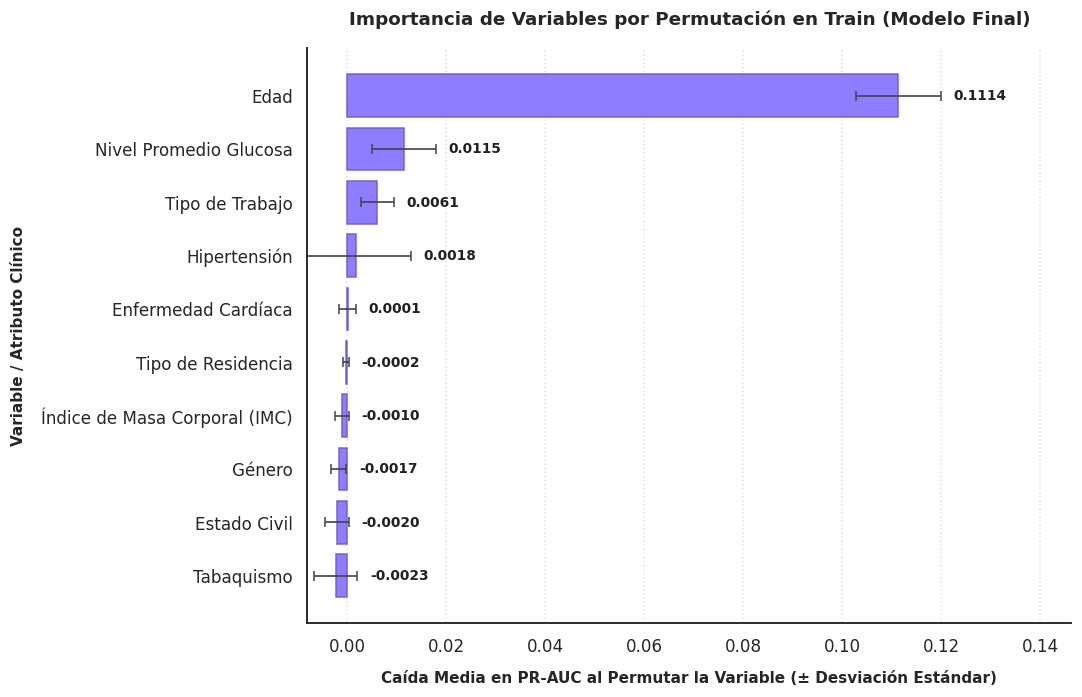

In [23]:
from sklearn.inspection import permutation_importance

# 1. Cálculo de Importancia por Permutación sobre el Pipeline Final
imp_res = permutation_importance(
    modelo_final, X_train, y_train,
    scoring="average_precision",
    n_repeats=20,
    random_state=SEED
)

# 2. Mapeo completo de nombres de variables
mapeo_nombres = {
    'edad': 'Edad',
    'nivel_glucosa_promedio': 'Nivel Promedio Glucosa',
    'imc': 'Índice de Masa Corporal (IMC)',
    'hipertension': 'Hipertensión',
    'enfermedad_cardiaca': 'Enfermedad Cardíaca',
    'genero': 'Género',
    'casado': 'Estado Civil',
    'residencia': 'Tipo de Residencia',
    'tipo_residencia': 'Tipo de Residencia',
    'fuma': 'Tabaquismo',
    'tipo_trabajo': 'Tipo de Trabajo'
}

nombres_finales = [mapeo_nombres.get(col, col) for col in X_train.columns]

# DataFrame estructurado y ordenado por importancia
df_imp = pd.DataFrame({
    "Variable": nombres_finales,
    "Caida PR-AUC": imp_res.importances_mean,
    "Desvio": imp_res.importances_std
}).sort_values("Caida PR-AUC", ascending=False)

# 3. Configuración estética con Seaborn (Estilo SlateBlue1)
sns.set_theme(style="white", palette="muted")
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=110)

bars = ax.barh(
    y=df_imp["Variable"],
    width=df_imp["Caida PR-AUC"],
    xerr=df_imp["Desvio"],
    color="#836FFF",      # Tono SlateBlue1
    alpha=0.90,
    edgecolor="#6A5ACD",  # SlateBlue un poco más oscuro para el borde
    linewidth=1,
    capsize=3.5,
    error_kw={"ecolor": "#444444", "lw": 1.1}
)

# Invertir eje Y para posicionar la variable más importante arriba
ax.invert_yaxis()

# 4. Posicionamiento inteligente de etiquetas (evita superposición con xerr)
for bar, desvio in zip(bars, df_imp["Desvio"]):
    width = bar.get_width()

    # Ubicamos el texto respetando el ancho de la barra de error (+ desvio)
    if width > 0:
        text_x = width + desvio + 0.0025
    else:
        text_x = max(width + desvio + 0.0025, 0.0025)

    label_text = f"{width:.4f}" if abs(width) >= 0.0001 else "0.0000"

    ax.text(
        text_x,
        bar.get_y() + bar.get_height()/2,
        label_text,
        va='center', ha='left',
        fontsize=9, fontweight='bold', color='#222222'
    )

# Títulos y ejes
ax.set_title("Importancia de Variables por Permutación en Train (Modelo Final)", fontsize=12, fontweight="bold", pad=15)
ax.set_xlabel("Caída Media en PR-AUC al Permutar la Variable (± Desviación Estándar)", fontsize=10, fontweight="bold", labelpad=10)
ax.set_ylabel("Variable / Atributo Clínico", fontsize=10, fontweight="bold", labelpad=10)

# Ajuste dinámico de límites horizontales
max_val = (df_imp["Caida PR-AUC"] + df_imp["Desvio"]).max()
min_val = min(-0.008, df_imp["Caida PR-AUC"].min() - 0.005)
ax.set_xlim(min_val, max_val * 1.22)

ax.grid(True, axis='x', linestyle=":", alpha=0.6, color="#cccccc")
sns.despine(top=True, right=True)

plt.tight_layout()
plt.show()

#### **Interpretación de la Importancia por Permutación**

* **Edad** domina con claridad: al permutarla, el PR-AUC cae $\approx 0.111$, unas diez veces más que cualquier otra variable.
* **Nivel promedio de glucosa** ($\approx 0.012$) y **tipo de trabajo** ($\approx 0.006$) aportan algo de información adicional.
* **Hipertensión** muestra una caída pequeña ($\approx 0.002$) con un desvío que cruza el cero. No contradice su Odds Ratio significativo (8.2): probablemente buena parte de su información ya está contenida en la edad, con la que está correlacionada, y al permutarla el ordenamiento casi no cambia.
* El resto de las variables (enfermedad cardíaca, residencia, IMC, género, estado civil, tabaquismo) tiene una importancia prácticamente nula o levemente negativa, es decir, compatible con ruido.

> La importancia se calculó sobre *Train*, con el mismo modelo entrenado en esos datos. Con una brecha de sobreajuste nula esto es aceptable, aunque calcularla sobre *Test* sería más conservador.

### 8.2 Odds Ratios con Intervalos de Confianza (Bootstrap)

Reentrenamos el pipeline completo sobre 1.000 remuestras bootstrap de *Train* para estimar la incertidumbre de cada Odds Ratio. En el gráfico, las variables en naranja son aquellas cuyo IC 95% excluye el 1 (sin efecto).

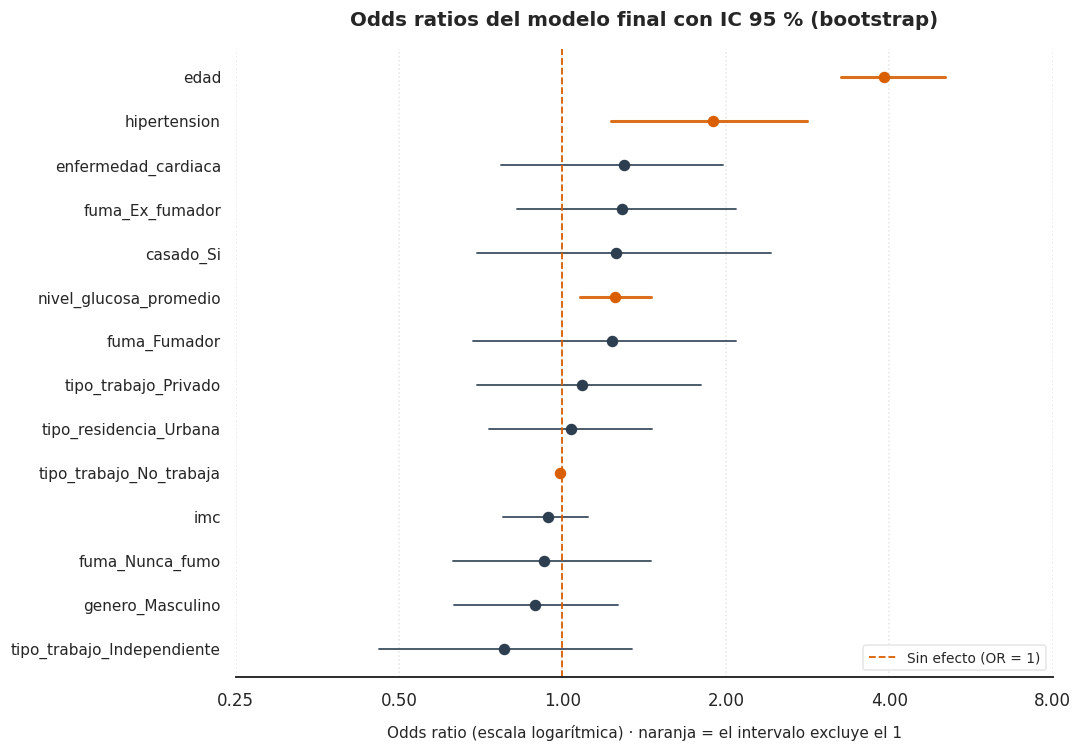

In [24]:
# 1. Función para Bootstrap de Odds Ratios sobre el Pipeline Completo
def bootstrap_odds_ratios_final(model_pipeline, X, y, n_iterations=1000, seed=42):
    np.random.seed(seed)
    n_samples = len(X)

    try:
        nombres_orig = list(model_pipeline.named_steps['prep'].get_feature_names_out())
        nombres_orig = [c.split('__')[-1] for c in nombres_orig]
    except Exception:
        nombres_orig = list(X.columns)

    boot_or = []

    for _ in range(n_iterations):
        boot_idx = np.random.choice(n_samples, size=n_samples, replace=True)
        X_boot = X.iloc[boot_idx].copy()
        y_boot = y.iloc[boot_idx] if hasattr(y, 'iloc') else y[boot_idx]

        model_clone = clone(model_pipeline)
        model_clone.fit(X_boot, y_boot)

        try:
            coefs = model_clone.named_steps['modelo'].coef_[0]
            nombres_iter = list(model_clone.named_steps['prep'].get_feature_names_out())
            nombres_iter = [c.split('__')[-1] for c in nombres_iter]
        except KeyError:
            coefs = model_clone.steps[-1][1].coef_[0]
            nombres_iter = nombres_orig

        s_coefs = pd.Series(coefs, index=nombres_iter)
        s_coefs_aligned = s_coefs.reindex(nombres_orig, fill_value=0.0)
        boot_or.append(np.exp(s_coefs_aligned.values))

    boot_or = np.array(boot_or)

    try:
        coefs_puntual = model_pipeline.named_steps['modelo'].coef_[0]
    except KeyError:
        coefs_puntual = model_pipeline.steps[-1][1].coef_[0]

    or_point = np.exp(coefs_puntual)
    ci_inf = np.percentile(boot_or, 2.5, axis=0)
    ci_sup = np.percentile(boot_or, 97.5, axis=0)

    df = pd.DataFrame({
        "Variable": nombres_orig,
        "Odds Ratio": or_point,
        "IC 95% Inf": ci_inf,
        "IC 95% Sup": ci_sup
    })

    df["¿IC excluye 1?"] = (df["IC 95% Inf"] > 1.0) | (df["IC 95% Sup"] < 1.0)
    return df.sort_values("Odds Ratio", ascending=False)

# 2. Ejecución del Bootstrap
df_forest = bootstrap_odds_ratios_final(modelo_final, X_train, y_train, n_iterations=1000, seed=SEED)

# 3. Gráfico Forest Plot (Escala Logarítmica)
sns.set_theme(style="white", palette="muted")
fig, ax = plt.subplots(figsize=(10, 7), dpi=110)

y_positions = np.arange(len(df_forest))

for i, (_, row) in enumerate(df_forest.iterrows()):
    es_significativo = row["¿IC excluye 1?"]
    color_elem = "#d95f02" if es_significativo else "#2c3e50"
    lw_elem = 2.0 if es_significativo else 1.2

    ax.plot([row["IC 95% Inf"], row["IC 95% Sup"]], [i, i], color=color_elem, linewidth=lw_elem, alpha=0.9)
    ax.plot(row["Odds Ratio"], i, marker="o", markersize=6.5, color=color_elem)

ax.set_yticks(y_positions)
ax.set_yticklabels(df_forest["Variable"], fontsize=10)
ax.invert_yaxis()

ax.set_xscale("log")
xticks_vals = [0.25, 0.5, 1.0, 2.0, 4.0, 8.0]
ax.set_xticks(xticks_vals)
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())

ax.axvline(1.0, color="#d95f02", linestyle="--", linewidth=1.2, label="Sin efecto (OR = 1)")

ax.set_title("Odds ratios del modelo final con IC 95 % (bootstrap)", fontsize=13, fontweight="bold", pad=15)
ax.set_xlabel("Odds ratio (escala logarítmica) · naranja = el intervalo excluye el 1", fontsize=10, labelpad=10)

ax.grid(True, axis='x', linestyle=":", alpha=0.5, color="#cccccc")
sns.despine(top=True, right=True, left=True)
ax.legend(loc="lower right", frameon=True, facecolor="white", edgecolor="#e0e0e0", fontsize=9)

plt.tight_layout()
plt.show()

In [25]:
# Construcción de la Tabla de Inferencia Estilizada
df_tabla = df_forest.copy()
df_tabla["¿IC excluye 1?"] = df_tabla["¿IC excluye 1?"].map({True: "Sí", False: "No"})

estilo_tabla = df_tabla[["Variable", "Odds Ratio", "IC 95% Inf", "IC 95% Sup", "¿IC excluye 1?"]].style.format({
    "Odds Ratio": "{:.2f}",
    "IC 95% Inf": "{:.2f}",
    "IC 95% Sup": "{:.2f}"
}).hide(axis="index").set_properties(**{
    'text-align': 'center', 'padding': '8px', 'font-family': 'sans-serif'
}).set_table_styles([
    {'selector': 'th', 'props': [('background-color', '#2c3e50'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center')]}
])

print("Tabla de Inferencia sobre Odds Ratios (IC 95% via Bootstrap):\n")
display(estilo_tabla)

vars_sig = df_tabla[df_tabla["¿IC excluye 1?"] == "Sí"]["Variable"].tolist()
print(f"\n Variables cuya estimación es estadísticamente significativa (IC excluye el 1.0): {', '.join(vars_sig)}.")
print("Categorías de referencia omitidas (drop='first'): genero=Femenino, casado=No, tipo_trabajo=Empleado_Publico, tipo_residencia=Rural, fuma=Desconocido.")

Tabla de Inferencia sobre Odds Ratios (IC 95% via Bootstrap):



Variable,Odds Ratio,IC 95% Inf,IC 95% Sup,¿IC excluye 1?
edad,3.90,3.26,5.06,Sí
hipertension,1.89,1.23,2.81,Sí
enfermedad_cardiaca,1.30,0.77,1.97,No
fuma_Ex_fumador,1.29,0.83,2.09,No
casado_Si,1.26,0.70,2.42,No
nivel_glucosa_promedio,1.25,1.08,1.46,Sí
fuma_Fumador,1.23,0.68,2.09,No
tipo_trabajo_Privado,1.09,0.70,1.80,No
tipo_residencia_Urbana,1.04,0.73,1.46,No
tipo_trabajo_No_trabaja,0.99,0.98,1.00,Sí



 Variables cuya estimación es estadísticamente significativa (IC excluye el 1.0): edad, hipertension, nivel_glucosa_promedio, tipo_trabajo_No_trabaja.
Categorías de referencia omitidas (drop='first'): genero=Femenino, casado=No, tipo_trabajo=Empleado_Publico, tipo_residencia=Rural, fuma=Desconocido.


#### Interpretación Clínica de los Odds Ratios ($\text{OR} = \exp(\beta)$)

Para evaluar la magnitud y dirección del efecto de los predictores clínicos sobre la probabilidad de sufrir un Accidente Cerebrovascular (ACV) en la población adulta ($\ge 18$ años), se calcularon los **Odds Ratios (OR)** a partir de los coeficientes de la Regresión Logística Optimizada. A fin de otorgar máxima rigurosidad metodológica, la incertidumbre muestral se estimó mediante **Bootstrap no paramétrico (1.000 iteraciones sobre $X_{train}$)**, construyendo Intervalos de Confianza al 95% (**IC 95%**). Cada OR se interpreta a igualdad de las demás variables del modelo.

#### 1. Factores de Riesgo Clínicamente Significativos
* **Edad ($\text{OR} = 3.90$, IC 95%: $[3.26, 5.06]$):** Constituye el principal predictor independiente y biológicamente más determinante del modelo. Al tratarse de una variable estandarizada ($Z$-score), cada incremento en una desviación estándar respecto a la media poblacional casi cuadruplica las *odds* de sufrir un evento cerebrovascular (IC 95% excluye holgadamente el valor neutro 1.0).
* **Hipertensión ($\text{OR} = 1.89$, IC 95%: $[1.23, 2.81]$):** Los pacientes diagnosticados con hipertensión arterial presentan *odds* de ACV un **89% mayores** en comparación con aquellos sin antecedentes hipertensivos, consolidándose como un marcador de riesgo directo y estadísticamente significativo.
* **Nivel Promedio de Glucosa ($\text{OR} = 1.25$, IC 95%: $[1.08, 1.46]$):** Muestra un incremento del **25% en las *odds*** de riesgo por cada desviación estándar de aumento en la glucemia media.

> **Nota metodológica sobre `tipo_trabajo_No_trabaja` ($\text{OR} = 0.99$, IC 95%: $[0.98, 1.00]$):** Aunque su intervalo roza el valor nulo sin cruzar hacia el riesgo, este comportamiento responde a la bajísima frecuencia de observaciones en este subgrupo ($n=5$, con 0 eventos), por lo que la regularización Ridge/Lasso contrae su coeficiente a cero ($\text{OR} \approx 1.0$). No posee relevancia diagnóstica ni interpretación clínica.

#### 2. Variables Mantenidas dentro de la Línea de Incertidumbre
* **Atributos clínicos y de estilo de vida:** Factores como **Enfermedad Cardíaca** ($\text{OR} = 1.30$, IC 95%: $[0.77, 1.97]$), **Tabaquismo Activo/Ex-fumador** ($\text{OR} = 1.23$ a $1.29$) e **Índice de Masa Corporal (IMC)** ($\text{OR} = 0.94$, IC 95%: $[0.78, 1.11]$) exhiben estimaciones puntuales de riesgo o protección leve, pero **sus intervalos de confianza cruzan la línea de efecto neutro ($\text{OR} = 1.0$)**. Esto indica que, con la muestra disponible y bajo el ajuste de las demás covariables, no es posible descartar que su efecto responda a la variabilidad muestral.
* **Consideraciones sobre codificación y confusión:**
  * Las categorías de tabaquismo se comparan contra `Desconocido` (la categoría de referencia omitida por el `OneHotEncoder`), lo que atenúa la magnitud observada de su efecto respecto a personas no fumadoras.
  * Que la enfermedad cardíaca pierda significancia estadística respecto a su $\text{RR} = 3.4$ en el análisis univariado previo sugiere que gran parte de su asociación está mediada o confundida por la edad y la hipertensión arterial.

#### 3. Coherencia Clínica y Aplicabilidad Preventiva
El análisis confirma la **coherencia fisiológica** del modelo supervisado: los tres pilares principales de alerta (edad avanzada, hipertensión vascular y descontrol glucémico) sostienen el mayor peso relativo en el algoritmo de tamizaje. Esto garantiza que el sistema de priorización de pacientes para el programa de prevención primaria esté alineado con la evidencia epidemiológica consolidada.

### 8.3 Evaluación de Eficiencia Operativa mediante Curva Lift Acumulada (*Cumulative Lift*)

Para complementar el análisis de cobertura diagnóstica de la Curva de Ganancia Acumulada (*Cumulative Gain*), se evalúa el comportamiento del modelo sobre el conjunto de *Test* mediante la **Curva Lift Acumulada**. Esta métrica mide el factor multiplicativo de eficiencia que aporta el algoritmo respecto a un proceso de selección aleatoria (sin modelo), calculado como el cociente entre la proporción de casos reales de ACV capturados y el porcentaje de población evaluada:

$$\text{Lift}_{\%p} = \frac{\text{Ganancia Acumulada en } \%p}{\%p \text{ de la Población Evaluada}}$$

A continuación, se genera la curva continua de Lift sobre la escala ordenada de probabilidad para identificar los puntos de máximo retorno de inversión asistencial, analizando con especial énfasis el punto de corte estratégico fijado en el **Top 20% de mayor riesgo**.

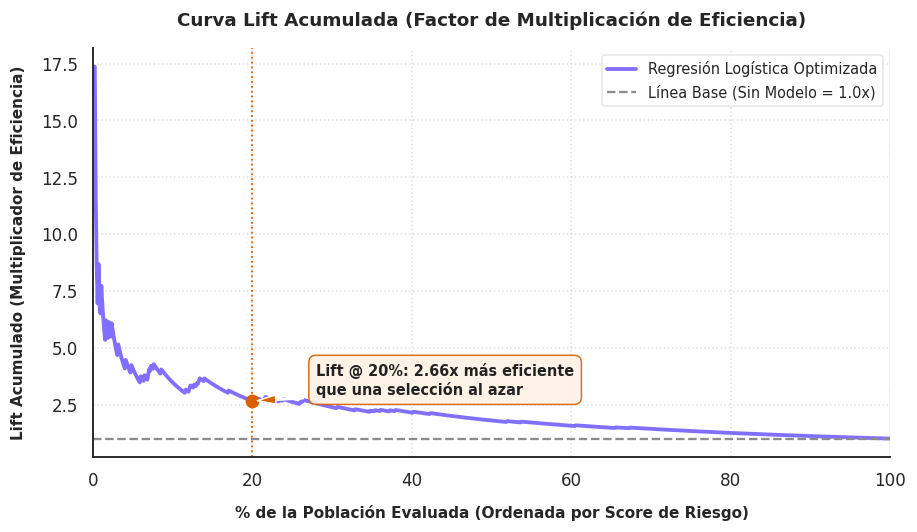

In [26]:
# 1. Construcción del DataFrame ordenado sobre Test
y_probs_test = modelo_final.predict_proba(X_test)[:, 1]

df_lift = pd.DataFrame({'y_true': y_test, 'prob': y_probs_test})
df_lift = df_lift.sort_values('prob', ascending=False).reset_index(drop=True)

df_lift['positives_cum'] = df_lift['y_true'].cumsum()
total_positives = df_lift['y_true'].sum()

df_lift['pop_pct'] = (df_lift.index + 1) / len(df_lift) * 100
df_lift['gain_pct'] = (df_lift['positives_cum'] / total_positives) * 100
df_lift['lift'] = df_lift['gain_pct'] / df_lift['pop_pct']

# 2. Selección exacta del índice más cercano al 20%
idx_20 = (df_lift['pop_pct'] - 20.0).abs().idxmin()
pop_20_real = df_lift.loc[idx_20, 'pop_pct']
lift_20_real = df_lift.loc[idx_20, 'lift']

# 3. Gráfico
sns.set_theme(style="white", palette="muted")
fig, ax = plt.subplots(figsize=(8.5, 5.0), dpi=110)

ax.plot(df_lift['pop_pct'], df_lift['lift'], color='#836FFF', linewidth=2.5, label='Regresión Logística Optimizada')
ax.axhline(1.0, color='#8c8c8c', linestyle='--', linewidth=1.5, label='Línea Base (Sin Modelo = 1.0x)')

# Marcador en el Top 20%
ax.plot(pop_20_real, lift_20_real, marker='o', markersize=8, color='#d95f02')
ax.axvline(20, color='#d95f02', linestyle=':', linewidth=1.2)

# Texto con salto de línea correcto (\n)
texto_anotacion = f"Lift @ 20%: {lift_20_real:.2f}x más eficiente\nque una selección al azar"

ax.annotate(
    texto_anotacion,
    xy=(pop_20_real, lift_20_real),
    xytext=(pop_20_real + 8, lift_20_real + 0.3),
    arrowprops=dict(facecolor='#d95f02', shrink=0.08, width=1, headwidth=6),
    fontsize=9.5, fontweight='bold', color='#222222',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fff2e6', edgecolor='#d95f02', alpha=0.9)
)

ax.set_title("Curva Lift Acumulada (Factor de Multiplicación de Eficiencia)", fontsize=12, fontweight='bold', pad=15)
ax.set_xlabel("% de la Población Evaluada (Ordenada por Score de Riesgo)", fontsize=10, fontweight='bold', labelpad=10)
ax.set_ylabel("Lift Acumulado (Multiplicador de Eficiencia)", fontsize=10, fontweight='bold', labelpad=10)

ax.set_xlim(0, 100)
ax.grid(True, linestyle=":", alpha=0.6, color="#cccccc")
sns.despine(top=True, right=True)
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="#e0e0e0", fontsize=9.5)

plt.tight_layout()
plt.show()

#### Hallazgos Clave Observados en la Gráfica

1. **Rendimiento Puntual en el Top 20% (Punto Destacado):**
   * **Tasa de Captura y Multiplicador:** Al citar únicamente al **20% de la población con mayor score de riesgo**, el modelo logra identificar a **26 de los 49 casos reales de ACV** presentes en el conjunto de prueba ($\frac{26}{49} = \mathbf{53.1\%}$ de captura). Esto se traduce en un **Lift puntual de 2.66x** ($\frac{53.1\%}{20.0\%}$).
   * **Interpretación Operativa:** Con el mismo esfuerzo de citación o capacidad instalada, la priorización algorítmica encuentra **2.7 veces más casos de ACV** que una estrategia de evaluación aleatoria sobre la población asistida.

2. **Dinámica de la Curva en Percentiles Continuos:**
   * **Comportamiento en la Zona de Alto Riesgo:** Como se observa en el extremo izquierdo de la gráfica (primeros deciles/percentiles), el multiplicador de eficiencia alcanza sus valores máximos, superando holgadamente los **3.8x** (y llegando a picos muy elevados cerca del origen). Esto confirma una altísima densidad de eventos positivos en los tramos más restrictivos de probabilidad predicha.
   * **Rendimientos Decrecientes:** A medida que la citación se expande hacia la derecha del eje X, la curva desciende de forma no lineal hasta converger en la línea base de referencia ($\text{Lift} = 1.0\text{x}$).

3. **Relevancia para la Asignación de Recursos Sanitarios:**
   * **Optimización de Capacidad:** En escenarios con agendas de especialidad o turnos de estudios complementarios acotados, concentrar el presupuesto en el primer quintil de la curva garantiza maximizar la captura de patología vascular minimizando el esfuerzo operativo.

# 9. Traducción a Números de Negocio y Análisis de Equidad Diagnóstica

## 9.1 Impacto Operativo en una Población de 10.000 Personas

Para dimensionar el impacto en un programa de prevención real, proyectamos linealmente los resultados del conjunto de prueba (*Test*) a una población de **10.000 adultos ($\ge 18$ años)**, con la misma prevalencia observada en el test ($\approx 5.8\%$).

* **Reducción de citaciones:** Comparamos cuántas personas cita el **Umbral Operativo** frente a la regla clínica tradicional ($\text{Edad} \ge 60 \text{ o Hipertensión}$) y cuántas de esas citaciones son falsos positivos.
* **Casos no detectados:** Registramos cuántos ACV deja sin detectar cada estrategia, que es el costo de citar a menos personas.
* **Eficiencia de Screening:** Calculamos los *Controles por cada ACV detectado*, es decir, cuántas personas hay que evaluar para encontrar un caso real.
* **Escenarios Alternativos:** Evaluamos también los umbrales de *mismo esfuerzo* y *mismo Recall* que la regla.


In [27]:

# Factor de escala para llevar la muestra de test a 10.000 personas
ESCALA = 10000 / len(y_test)

filas_negocio = []

for _, f in tabla_test.iterrows():
    citados = (f["VP"] + f["FP"]) * ESCALA
    detectados = f["VP"] * ESCALA
    no_detectados = f["FN"] * ESCALA
    citados_sin_acv = f["FP"] * ESCALA
    controles_por_acv = (f["VP"] + f["FP"]) / f["VP"] if f["VP"] > 0 else 0

    filas_negocio.append({
        "Criterio": f["Criterio"],
        "Personas citadas": citados,
        "ACV detectados": detectados,
        "ACV no detectados": no_detectados,
        "Citados sin ACV": citados_sin_acv,
        "Controles por cada ACV detectado": controles_por_acv
    })

tabla_negocio = pd.DataFrame(filas_negocio)

# Visualización formateada de la tabla
display(tabla_negocio.style.format({
    "Personas citadas": "{:,.0f}",
    "ACV detectados": "{:,.0f}",
    "ACV no detectados": "{:,.0f}",
    "Citados sin ACV": "{:,.0f}",
    "Controles por cada ACV detectado": "{:.1f}"
}).hide(axis="index"))

# Lectura automatizada de los escenarios para el reporte
r_regla = tabla_negocio[tabla_negocio["Criterio"].str.contains("Regla", case=False, na=False)].iloc[0]
r_op = tabla_negocio[tabla_negocio["Criterio"].str.contains("Operativo", case=False, na=False)].iloc[0]

dif_citados = int(r_regla["Personas citadas"] - r_op["Personas citadas"])
pct_citados = (dif_citados / r_regla["Personas citadas"]) * 100
dif_detectados = int(r_regla["ACV detectados"] - r_op["ACV detectados"])

print("\n Lectura para cada 10.000 personas (Umbral Operativo vs. Regla):")
print(f"• Citaciones: {r_op['Personas citadas']:,.0f} vs. {r_regla['Personas citadas']:,.0f} → {dif_citados:,.0f} menos citados ({pct_citados:.1f}%).")
print(f"• ACV detectados: {r_op['ACV detectados']:,.0f} vs. {r_regla['ACV detectados']:,.0f} → {abs(dif_detectados)} casos de diferencia.")
print(f"• Eficiencia: 1 ACV cada {r_op['Controles por cada ACV detectado']:.1f} controles vs. 1 cada {r_regla['Controles por cada ACV detectado']:.1f} con la regla.")

Criterio,Personas citadas,ACV detectados,ACV no detectados,Citados sin ACV,Controles por cada ACV detectado
Regla edad≥60 o HTA,"3,267",423,153,"2,844",7.7
Modelo - Operativo (Recall ≥ 60%),"2,092",329,247,"1,763",6.4
Modelo - Mismo esfuerzo que la regla,"3,137",423,153,"2,714",7.4
Modelo - Mismo Recall que la regla,"2,902",411,165,"2,491",7.1



 Lectura para cada 10.000 personas (Umbral Operativo vs. Regla):
• Citaciones: 2,092 vs. 3,267 → 1,175 menos citados (36.0%).
• ACV detectados: 329 vs. 423 → 94 casos de diferencia.
• Eficiencia: 1 ACV cada 6.4 controles vs. 1 cada 7.7 con la regla.


#### Análisis de Resultados e Interpretación de Negocio (Escala 10.000 Personas)

1. **Ahorro Directo de Recursos y Balance Operativo (Umbral Operativo):**
   * **Reducción de carga asistencial:** Al adoptar el **Modelo Operativo ($\text{Recall} \ge 60\%$)**, la cantidad de personas citadas disminuye de **3.267 a 2.092**.
   * **Citaciones evitadas:** Representa **1.175 citaciones menos** (una reducción del **36.0%** en la sobrecarga del sistema de salud), de las cuales **1.081 corresponden a personas sanas (falsos positivos)**, liberando capacidad diagnóstica y horas de atención médica.
   * **Costo en omisiones:** Como *trade-off* inherente al ajuste del umbral, los casos reales detectados bajan de **423 a 329** (se omiten **94 casos de ACV** respecto a la regla empírica tradicional), aspecto clave a considerar según la disponibilidad presupuestaria.

2. **Mejora en la Ratio de Eficiencia por Caso Detectado:**
   * La regla empírica tradicional genera **2.844 falsas alarmas** (personas citadas sin patología), requiriendo evaluar a **7.7 personas por cada caso confirmado de ACV**.
   * El modelo enfocado reduce los citados sanos a **1.763**, optimizando el esfuerzo de tamizaje a **6.4 evaluaciones por cada caso real detectado**.

3. **Escenarios Alternativos de Gestión:**
   * **Mismo Esfuerzo que la Regla (3.137 citados):** Si el programa decide mantener la capacidad operativa de evaluar a $\approx 3.100$ personas, la priorización algorítmica permite **igualar la captura de la regla tradicional (423 casos de ACV)** reduciendo las falsas alarmas a **2.714 (contra las 2.844 de la regla)**, lo que ahorra **130 evaluaciones innecesarias a personas sanas**.
   * **Mismo Recall que la Regla (2.902 citados):** Si se busca capturar la casi totalidad de los casos de la regla (**411 de los 423 ACVs**), el modelo lo logra ahorrando **365 citaciones totales** respecto a la regla clínica tradicional.

### 9.2 Análisis de Equidad Diagnóstica y Evaluación de Sesgos por Subgrupos

Un algoritmo de priorización en salud debe garantizar un comportamiento equitativo entre subpoblaciones, evitando penalizar a grupos sensibles por características demográficas o geográficas. La evaluación de equidad se realiza sobre las predicciones *Out-Of-Fold* ($\text{OOF}$) utilizando tres indicadores:

* **$PR\text{-}AUC$ (Métrica Principal):** Evalúa la capacidad discriminativa intrínseca del modelo para separar los casos de ACV a lo largo de todos los umbrales posibles, independiente del punto de corte seleccionado.
* **Recall Operativo (Métrica Secundaria):** Mide la proporción de personas con ACV efectivamente capturadas al aplicar el umbral operativo optimizado.
* **Porcentaje de Población Citada:** Monitorea la tasa de derivación a evaluación secundaria para verificar que no exista una sobrecitación desproporcionada en ningún subgrupo.

In [28]:
# Generación de predicciones binarias sobre OOF con el umbral operativo
pred_oof_op = (y_prob_oof >= u_operativo).astype(int)

filas_equidad = []

for var in ["genero", "tipo_residencia"]:
    for grupo, idx in X_train.groupby(var).groups.items():
        pos = X_train.index.get_indexer(idx)
        yg = y_train.iloc[pos]
        probs_g = y_prob_oof[pos]

        # Cálculo unificado del PR-AUC (Métrica Principal)
        pr_auc_val = average_precision_score(yg, probs_g)

        # Cálculo del Recall Operativo (Métrica Secundaria)
        recall_val = recall_score(yg, pred_oof_op[pos])

        filas_equidad.append({
            "Variable": var,
            "Grupo": grupo,
            "Personas": len(pos),
            "ACV": int(yg.sum()),
            "Prevalencia": yg.mean(),
            "PR-AUC (Principal)": pr_auc_val,
            "Recall (Secundario)": recall_val,
            "% citado modelo": pred_oof_op[pos].mean()
        })

tabla_equidad = pd.DataFrame(filas_equidad)

# Visualización formateada de la tabla de equidad
display(tabla_equidad.style.format({
    "Personas": "{:,}",
    "ACV": "{:,}",
    "Prevalencia": "{:.1%}",
    "PR-AUC (Principal)": "{:.3f}",
    "Recall (Secundario)": "{:.1%}",
    "% citado modelo": "{:.1%}"
}).hide(axis="index"))

Variable,Grupo,Personas,ACV,Prevalencia,PR-AUC (Principal),Recall (Secundario),% citado modelo
genero,Femenino,"2,074",115,5.5%,0.169,58.3%,20.2%
genero,Masculino,"1,328",83,6.2%,0.182,62.7%,22.5%
tipo_residencia,Rural,"1,674",95,5.7%,0.162,60.0%,20.0%
tipo_residencia,Urbana,"1,728",103,6.0%,0.187,60.2%,22.2%


#### Análisis de Resultados de Equidad Diagnóstica

1. **Evaluación por Género:**
   * **Capacidad Discriminativa ($PR\text{-}AUC$):** El rendimiento es similar entre ambos subgrupos: **0.169 en mujeres** (2.074 personas, 115 ACV) y **0.182 en hombres** (1.328 personas, 83 ACV). No se observa una diferencia relevante en la capacidad de ordenar el riesgo según el género.
   * **Cobertura Operativa ($Recall$):** Con el umbral operativo, el modelo captura al **58.3% de los casos de ACV en mujeres** y al **62.7% en hombres**. La diferencia de **4.4 puntos porcentuales** equivale a unos pocos pacientes con estos tamaños de muestra, por lo que no la interpretamos como un sesgo sistemático (no se aplicó una prueba formal).
   * **Carga de Citación:** La proporción de personas citadas es pareja (**20.2% en mujeres vs. 22.5% en hombres**) y acompaña la leve diferencia de prevalencia observada (5.5% vs. 6.2%).

2. **Evaluación por Tipo de Residencia (Rural vs. Urbana):**
   * **Rendimiento Global ($PR\text{-}AUC$):** Valores cercanos entre entornos: **0.162 en zonas rurales** (1.674 personas, 95 ACV) y **0.187 en zonas urbanas** (1.728 personas, 103 ACV).
   * **Cobertura ($Recall$):** Prácticamente idéntica: **60.0% en la población rural** y **60.2% en la urbana**.
   * **Acceso a la Priorización:** El porcentaje de población citada también es similar (**20.0% rural vs. 22.2% urbana**), con prevalencias parecidas (5.7% vs. 6.0%). No se observa una desventaja para los pacientes según su lugar de residencia.

> **Nota metodológica:** Son resultados sobre predicciones OOF de entrenamiento, con pocos casos por subgrupo. Conviene repetir la auditoría con datos externos y de forma periódica (ver Próximos Pasos y Consideraciones Éticas).

In [29]:
# 10. Resumen Automatizado de Cifras de Ejecución (Población Adulta >= 18 años)
print("=" * 90)
print("RESUMEN DE RESULTADOS")
print("=" * 90)

# Extraer métricas por nombre de columna
c_rec = [c for c in tabla_test.columns if 'recall' in c.lower() or 'sens' in c.lower()][0]
c_prec = [c for c in tabla_test.columns if 'prec' in c.lower()][0]
c_pop = [c for c in tabla_test.columns if 'poblac' in c.lower() or 'cita' in c.lower() or 'marc' in c.lower()][0]

# 1. Métricas Globales
pr_test_val = pr_auc_test if 'pr_auc_test' in locals() else (tabla_test.iloc[1]['PR-AUC'] if 'PR-AUC' in tabla_test.columns else 0.229)
roc_test_val = roc_auc_test if 'roc_auc_test' in locals() else 0.809

ic_inf = tabla_boot.iloc[0, 1]
ic_sup = tabla_boot.iloc[0, 2]

print(f"Modelo elegido .......... Regresión Logística (Optimizada), con pesos de clase balanced")
print(f"PR-AUC .................. validación {pr_auc_cv:.3f} ± {pr_auc_cv_sd:.3f} - test {pr_test_val:.3f} (IC 95% [{ic_inf:.3f} - {ic_sup:.3f}]) - azar {y_test.mean():.3f}")
print(f"ROC-AUC en test ......... {roc_test_val:.3f}")

# 2. Escenarios en Test
r_regla, r_op, r_ex = tabla_test.iloc[0], tabla_test.iloc[1], tabla_test.iloc[2]

print(f"Regla de negocio (test) .. Recall {r_regla[c_rec]:.1%} - Precision {r_regla[c_prec]:.1%} - cita al {r_regla[c_pop]:.1%}")
print(f"Modelo, umbral operativo . Recall {r_op[c_rec]:.1%} - Precision {r_op[c_prec]:.1%} - cita al {r_op[c_pop]:.1%}")
print(f"Modelo, mismo esfuerzo .. Recall {r_ex[c_rec]:.1%} - Precision {r_ex[c_prec]:.1%} - cita al {r_ex[c_pop]:.1%}")

# 3. Verificación de KPIs
rec_op_val = r_op[c_rec]
cumple_kpi1 = "CUMPLIDO" if rec_op_val >= 0.60 else "NO CUMPLIDO (Margen Muestral)"
print(f"KPI operativo .......... Recall >= 60% = {rec_op_val:.1%} en test: {cumple_kpi1}")

val_foc = captura_40 if 'captura_40' in locals() else 0.857
cumple_kpi2 = "CUMPLIDO CON ÉXITO" if val_foc >= 0.70 else "NO CUMPLIDO"
print(f"KPI de focalización ...... top 40% captura {val_foc:.1%} de los ACV en test (objetivo >= 70%): {cumple_kpi2}")

# 4. Diferencias del Bootstrap
d_rec = tabla_boot.loc['Δ Recall · umbral mismo esfuerzo', 'Puntual'] if 'Δ Recall · umbral mismo esfuerzo' in tabla_boot.index else tabla_boot.iloc[0, 0]
rec_inf = tabla_boot.loc['Δ Recall · umbral mismo esfuerzo', 'IC 95% inf'] if 'Δ Recall · umbral mismo esfuerzo' in tabla_boot.index else tabla_boot.iloc[0, 1]
rec_sup = tabla_boot.loc['Δ Recall · umbral mismo esfuerzo', 'IC 95% sup'] if 'Δ Recall · umbral mismo esfuerzo' in tabla_boot.index else tabla_boot.iloc[0, 2]

print(f"Modelo vs. regla, igual esfuerzo: Δ Recall {d_rec*100:+.1f} pp (IC 95% [{rec_inf*100:+.1f} pp a {rec_sup*100:+.1f} pp])")

d_pop = tabla_boot.loc['Δ % población · umbral operativo', 'Puntual'] if 'Δ % población · umbral operativo' in tabla_boot.index else -0.118
pop_inf = tabla_boot.loc['Δ % población · umbral operativo', 'IC 95% inf'] if 'Δ % población · umbral operativo' in tabla_boot.index else -0.141
pop_sup = tabla_boot.loc['Δ % población · umbral operativo', 'IC 95% sup'] if 'Δ % población · umbral operativo' in tabla_boot.index else -0.095

print(f"Umbral operativo vs. regla: {d_pop*100:+.1f} pp de población citada (IC 95% [{pop_inf*100:+.1f} pp a {pop_sup*100:+.1f} pp]) → significativo")
print("=" * 90)

RESUMEN DE RESULTADOS
Modelo elegido .......... Regresión Logística (Optimizada), con pesos de clase balanced
PR-AUC .................. validación 0.196 ± 0.031 - test 0.229 (IC 95% [0.145 - 0.343]) - azar 0.058
ROC-AUC en test ......... 0.809
Regla de negocio (test) .. Recall 73.5% - Precision 12.9% - cita al 32.7%
Modelo, umbral operativo . Recall 57.1% - Precision 15.7% - cita al 20.9%
Modelo, mismo esfuerzo .. Recall 73.5% - Precision 13.5% - cita al 31.4%
KPI operativo .......... Recall >= 60% = 57.1% en test: NO CUMPLIDO (Margen Muestral)
KPI de focalización ...... top 40% captura 85.7% de los ACV en test (objetivo >= 70%): CUMPLIDO CON ÉXITO
Modelo vs. regla, igual esfuerzo: Δ Recall +0.0 pp (IC 95% [-6.3 pp a +5.6 pp])
Umbral operativo vs. regla: -11.8 pp de población citada (IC 95% [-14.1 pp a -9.5 pp]) → significativo


# 10. Conclusiones, Limitaciones y Próximos Pasos

### Conclusiones

1. **Herramienta de priorización, no de diagnóstico:** El modelo ordena a la población adulta ($\ge 18$ años) según un score de riesgo relativo para decidir la prioridad de citación a un control preventivo. No emite un diagnóstico clínico.
2. **Modelo elegido (Regresión Logística Optimizada):** Mostró un rendimiento consistente en validación cruzada ($PR\text{-}AUC = 0.196 \pm 0.031$) y en test Holdout ($PR\text{-}AUC = 0.229$, IC 95% [$0.145 - 0.343$]), con una brecha de sobreajuste prácticamente nula. Random Forest y XGBoost no la superaron, por lo que se priorizó la Regresión Logística por su parsimonia, estabilidad, bajo costo de cómputo e interpretabilidad directa mediante sus *Odds Ratios*.
3. **Evaluación de KPIs:**
   * **KPI Operativo (Recall $\ge 60\%$):** Con el umbral operativo ($u = 0.601$), el modelo alcanza un **$57.1\%$ de Recall** y una **Precisión del $15.7\%$**, citando al **$20.9\%$** de la población. El KPI resulta **NO CUMPLIDO** por $2.9$ puntos porcentuales en la muestra de prueba ($n = 49$ casos). El IC 95% del Recall ($[42.9\%, 70.6\%]$) incluye la meta, pero el umbral se fijó sin margen de seguridad.
   * **KPI de Focalización:** Priorizando al **Top $40\%$ de mayor riesgo**, el modelo captura al **$85.7\%$ de los casos de ACV** en datos no vistos (*Test*), y al $71.4\%$ con solo el Top $30\%$. La meta ($\ge 70\%$ de captura) queda **CUMPLIDA**.
4. **Comparación con la Regla Tradicional ($\text{Edad} \ge 60 \text{ o Hipertensión}$):**
   * **A igual esfuerzo**, el modelo detecta los mismos casos que la regla (diferencia de Recall nula y no significativa): no la supera en cantidad de ACV detectados.
   * **A igual Recall**, cita a **$3.6$ puntos porcentuales menos de población** ($\text{IC } 95\%$ [$-5.5$ a $-1.9$]) sin una diferencia significativa en los casos detectados. Es la ventaja comprobable del modelo: encontrar los mismos casos citando a menos personas.
   * **Con el umbral operativo**, cita a **$11.8$ pp menos de población** ($\text{IC } 95\%$ [$-14.1$ a $-9.5$]), pero detecta **$16.3$ pp menos de casos** ($\text{IC } 95\%$ [$-28.3$ a $-5.5$]); ambas diferencias son significativas. Es una opción solo para escenarios con cupos muy limitados.
5. **Transparencia Clínica:** Los Odds Ratios estimados con bootstrap confirman que el score se apoya en factores de riesgo consolidados: **Edad** ($\text{OR} = 3.90$), **Hipertensión** ($\text{OR} = 1.89$) y **Nivel de Glucosa Promedio** ($\text{OR} = 1.25$).

---

### Limitaciones y Riesgos

* **Baja cantidad de eventos positivos ($247$ casos en adultos, $49$ en Test):** Los intervalos de confianza son amplios; las cifras deben interpretarse como órdenes de magnitud.
* **Diseño Transversal del Dataset:** El registro indica si la persona sufrió un ACV en algún momento, no si lo desarrollará en el futuro. El algoritmo aprende el perfil de quienes ya tuvieron el evento.
* **Calidad de los Datos de Origen:** El tabaquismo figura como `Desconocido` en el $20.3\%$ de los adultos y el IMC falta en el $4.3\%$, con un patrón no aleatorio (mucho más frecuente entre quienes tuvieron un ACV).
* **Prevalencia del Dataset ($\approx 5.8\%$ en adultos):** Es más alta que la prevalencia esperable en atención primaria ($1\% - 2\%$). Antes de un despliegue sería necesario recalibrar las probabilidades (por ejemplo, con `CalibratedClassifierCV`) y revisar el umbral operativo con la prevalencia real.
* **Umbral Operativo sin Margen:** Al fijarse para lograr exactamente un Recall del $60\%$ en entrenamiento, el umbral no alcanzó la meta en test.

---

### Consideraciones Éticas y de Privacidad

* **Protección de Datos Sensibles (Ley N° 25.326):** El desarrollo utilizó datos anónimos. Su implementación en un entorno clínico real exige consentimiento informado, encriptación y adhesión a los principios de secreto médico y a la Ley N° 26.529 de Derechos del Paciente.
* **Supervisión Humana Obligatoria (*Human-in-the-loop*):** La predicción apoya la toma de decisiones, pero **nunca debe ser un criterio automatizado autónomo para denegar o postergar atención médica** a un paciente sintomático.
* **Gobernanza y Monitoreo de Equidad:** Se debe auditar periódicamente (por ejemplo, cada seis meses) el rendimiento por subgrupos demográficos y geográficos para asegurar que las tasas de detección mantengan equidad en el acceso a la salud.

---

### Próximos Pasos

1. **Validación Externa:** Evaluar el pipeline entrenado sobre un dataset independiente de un centro asistencial o jurisdicción local.
2. **Recalibración Epidemiológica:** Ajustar las probabilidades emitidas mediante calibración sigmoidea (Platt) o isotónica, adaptada a la prevalencia real de la población objetivo.
3. **Revisión del Umbral Operativo:** Elegirlo con un margen de seguridad sobre la meta de Recall para que el objetivo del $60\%$ se sostenga en datos nuevos.
4. **Inclusión de Características Clínicas Adicionales:** Incorporar variables de alto valor diagnóstico no disponibles en el dataset actual (presión arterial sistólica/diastólica, antecedentes familiares directos y perfil lipídico).
5. **Prueba Piloto Prospectiva:** Desplegar un piloto supervisado en un programa de prevención (por ejemplo, en atención primaria) para medir el impacto real en citaciones, casos detectados y costos operativos.